In [ ]:
import marimo as mo

# AGIR — prompt_v3 Qwen stabilization
Phase A: CPU-only, reuses existing cached results — no model reload needed for §1, 3-7.
Phase B: GPU needed — critical RefCOCOg re-investigation (§8-13) before any localization claim.

Cell 1 — imports (lightweight, no model loading)

In [ ]:
import json, os, shutil
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.contingency_tables import mcnemar

Cell 2 — §1: freeze legacy outputs (upload your prior result files first)

In [ ]:
def freeze_legacy_outputs():
    os.makedirs("outputs_legacy/version4_qwen", exist_ok=True)
    files_to_preserve = [
        "qwen_corrected_final_results.json", "full_validation_all_configs.jsonl",
        "intervention_cache_deduped.jsonl", "extended_features_cache.jsonl",
        "refcoco_corrected_results.jsonl", "fusion_strategy_comparison.jsonl",
        "efficiency_results.jsonl", "category_level_analysis.json",
        "reproducibility_statement.json", "sanity_check_results.json",
    ]
    preserved, missing = [], []
    for fname in files_to_preserve:
        if os.path.exists(fname):
            shutil.copy(fname, f"outputs_legacy/version4_qwen/{fname}")
            preserved.append(fname)
        else:
            missing.append(fname)
    print(f"Preserved {len(preserved)} files: {preserved}")
    if missing:
        print(f"NOT FOUND (upload these if you need them preserved): {missing}")

freeze_legacy_outputs()

In [ ]:

# Create ZIP of the entire outputs_legacy folder
zip_path = shutil.make_archive(
    base_name="outputs_legacy",
    format="zip",
    root_dir="outputs_legacy"
)

print(f"ZIP created successfully: {zip_path}")

# Download button
download_button = mo.download(
    data=open(zip_path, "rb").read(),
    filename="outputs_legacy.zip",
    label="⬇️ Download outputs_legacy.zip",
)

download_button

Cell 3 — reconstitute the gate (CPU-only, exact same params as before, no GPU needed)

In [ ]:
class InterventionGate:
    def __init__(self):
        self.model = None
        self.scaler = None
    def fit(self, X, y):
        self.scaler = StandardScaler().fit(X)
        self.model = LogisticRegression(max_iter=1000, class_weight="balanced").fit(self.scaler.transform(X), y)
        return self
    def predict_proba(self, X):
        return self.model.predict_proba(self.scaler.transform(X))

def rebuild_final_gate(base_path="intervention_cache_deduped.jsonl", ext_path="extended_features_cache.jsonl"):
    # FIX: intervention_cache_deduped.jsonl alone doesn't have answer_confidence —
    # that only exists in extended_features_cache.jsonl. Merge by idx, same as the
    # original merge_caches() function, so this notebook doesn't depend on the old one.
    base = {}
    with open(base_path) as f:
        for line in f:
            r = json.loads(line)
            base[r["idx"]] = r
    ext = {}
    with open(ext_path) as f:
        for line in f:
            r = json.loads(line)
            ext[r["idx"]] = r

    merged = []
    for idx in sorted(base.keys()):
        merged.append({**base[idx], **ext.get(idx, {})})

    rows_with_confidence = [r for r in merged if "answer_confidence" in r and "error" not in r]
    X = np.array([[r["answer_confidence"]] for r in rows_with_confidence])
    y = np.array([1 if r["label"] == "beneficial" else 0 for r in rows_with_confidence])

    gate = InterventionGate().fit(X, y)
    print(f"Gate rebuilt on {len(X)} samples ({y.sum()} beneficial)")
    return gate

final_gate = rebuild_final_gate()

Gate rebuilt on 10000 samples (878 beneficial)


Cell 4 — §3/4: primary method = Confidence-Gated DINO Replay at τ=0.6

In [ ]:
TAU_PRIMARY = 0.6

def compute_primary_method(cache_path="full_validation_all_configs.jsonl", tau=TAU_PRIMARY):
    rows = [json.loads(l) for l in open(cache_path) if "error" not in json.loads(l)]

    acc_direct = np.array([r["acc_direct"] for r in rows])
    acc_dino = np.array([r["acc_dino_replay"] for r in rows])
    acc_native = np.array([r["acc_native_replay"] for r in rows])
    acc_fused = np.array([r["acc_fused_replay"] for r in rows])
    confidence = np.array([r["answer_confidence"] for r in rows])

    probs = final_gate.predict_proba(confidence.reshape(-1, 1))[:, 1]
    gate_decision = probs >= tau

    acc_agir_dino = np.where(gate_decision, acc_dino, acc_direct)

    print(f"n={len(rows)}, tau={tau}, replay_rate={gate_decision.mean():.1%}")
    print()
    print(f"Direct VLM:           {acc_direct.mean():.4f}")
    print(f"DINO replay (always): {acc_dino.mean():.4f}")
    print(f"Native replay:        {acc_native.mean():.4f}")
    print(f"Fused replay:         {acc_fused.mean():.4f}")
    print(f"AGIR (DINO, tau={tau}): {acc_agir_dino.mean():.4f}   <- NEW primary method result")

    return {
        "acc_direct": acc_direct, "acc_dino": acc_dino, "acc_native": acc_native,
        "acc_fused": acc_fused, "acc_agir_dino": acc_agir_dino, "gate_decision": gate_decision,
    }

primary_results = compute_primary_method()

Cell 5 — §5: McNemar + 10,000-resample bootstrap at τ=0.6

In [ ]:
def binarize(acc, thresh=0.5):
    return acc >= thresh

def mcnemar_test(a, b, name_a, name_b):
    a_bin, b_bin = binarize(a), binarize(b)
    table = [[np.sum(a_bin & b_bin), np.sum(a_bin & ~b_bin)],
             [np.sum(~a_bin & b_bin), np.sum(~a_bin & ~b_bin)]]
    result = mcnemar(table, exact=True)
    print(f"{name_a} vs {name_b}: statistic={result.statistic:.4f}, p={result.pvalue:.4f}, table={table}")
    return result.pvalue

def bootstrap_ci(a, b, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    diffs = a - b
    boots = [rng.choice(diffs, size=len(diffs), replace=True).mean() for _ in range(n_boot)]
    return diffs.mean(), np.percentile(boots, [2.5, 97.5])

print("=== McNemar (§5) ===")
mcnemar_test(primary_results["acc_agir_dino"], primary_results["acc_direct"], "AGIR-DINO", "Direct")
mcnemar_test(primary_results["acc_agir_dino"], primary_results["acc_dino"], "AGIR-DINO", "DINO-always")
mcnemar_test(primary_results["acc_agir_dino"], primary_results["acc_fused"], "AGIR-DINO", "Always-on(fused)")
print()
print("=== Paired bootstrap, 10,000 resamples (§5) ===")
results_summary = {}
for name, other_key in [("Direct", "acc_direct"), ("DINO-always", "acc_dino"), ("Always-on-fused", "acc_fused")]:
    diff, ci = bootstrap_ci(primary_results["acc_agir_dino"], primary_results[other_key])
    sig = "SIGNIFICANT" if (ci[0] > 0 or ci[1] < 0) else "not significant (CI includes 0)"
    print(f"AGIR-DINO vs {name}: diff={diff:.4f}, 95% CI=[{ci[0]:.4f}, {ci[1]:.4f}] — {sig}")
    results_summary[f"AGIR-DINO_vs_{name}"] = {"diff": diff, "ci": list(ci), "significant": bool(ci[0] > 0 or ci[1] < 0)}

with open("primary_method_stats.json", "w") as f:
    json.dump(results_summary, f, indent=2)

Cell 6 — §6/7: document verifier and fusion as ablations

In [ ]:
def document_ablation_findings():
    findings = {
        "verifier": {
            "status": "ablation only, not in primary method",
            "finding": "A secondary answer-verification stage did not improve the "
                        "uncertainty-gated replay pipeline (AGIR 64.80% vs AGIR+verifier 64.43%).",
        },
        "fusion": {
            "status": "ablation only, not a contribution claim",
            "finding": "Multi-expert fusion does not outperform DINO alone on either "
                        "RefCOCOg localization or A-OKVQA replay accuracy. Presented as a "
                        "negative finding; DINO replay is the preferred primary method "
                        "pending the corrected RefCOCOg benchmark (§8-13).",
        },
    }
    print(json.dumps(findings, indent=2))
    with open("ablation_findings_v3.json", "w") as f:
        json.dump(findings, f, indent=2)
document_ablation_findings()

Phase B: the critical RefCOCOg re-investigation.

Cell 7 — reload models (Qwen + DINO, needed for the diagnostic)

In [ ]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText, AutoModelForZeroShotObjectDetection
device = "cuda" if torch.cuda.is_available() else "cpu"

BACKBONE_ID = "Qwen/Qwen2.5-VL-7B-Instruct"
vlm_processor = AutoProcessor.from_pretrained(BACKBONE_ID)
vlm_model = AutoModelForImageTextToText.from_pretrained(BACKBONE_ID, dtype=torch.bfloat16, device_map=device)

DINO_ID = "IDEA-Research/grounding-dino-base"
dino_processor = AutoProcessor.from_pretrained(DINO_ID)
dino_model = AutoModelForZeroShotObjectDetection.from_pretrained(DINO_ID).to(device)

mo.md(f"Loaded on {device}")

Loading weights: 100%|██████████| 1182/1182 [00:00<00:00, 4333.59it/s]


<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Loaded on cuda</span></span>

In [ ]:

print("PyTorch:", torch.__version__)

try:
    import torchvision
    print("Torchvision:", torchvision.__version__)
except Exception as e:
    print("Torchvision ERROR:", repr(e))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130


Cell 8 — §9: try multiple RefCOCOg loaders, find the actual referring-expression field

In [ ]:
from datasets import load_dataset

GENERIC_PATTERNS = [
    "observe the area circled", "caption for the area", "describe the circled region",
    "what is in the circled region", "look at the circled area",
]

def is_generic(text):
    t = text.lower().strip()
    if len(t) == 0:
        return True
    if len(t.split()) < 2:
        return True
    return any(p in t for p in GENERIC_PATTERNS)

def try_load(name, splits=("val", "validation", "test")):
    for split in splits:
        try:
            return load_dataset(name, split=split), split
        except Exception:
            continue
    return None, None

def inspect_refcoco_candidates():
    """§9 — try several known RefCOCOg loaders and inspect every text-like field for
    a genuine referring expression vs. a generic captioning prompt."""
    candidates = ["lmms-lab/RefCOCOg", "jxu124/refcocog", "jxu124/refcoco"]
    found = {}
    for name in candidates:
        ds, split = try_load(name)
        if ds is None:
            print(f"{name}: FAILED to load with any known split name")
            continue
        sample = ds[0]
        print(f"\n=== {name} (split={split}) ===")
        print("Keys:", list(sample.keys()))
        for k, v in sample.items():
            if isinstance(v, str):
                flag = "GENERIC/SUSPECT" if is_generic(v) else "looks OK"
                print(f"  {k}: {repr(v[:150])}  [{flag}]")
        found[name] = (ds, split)
    return found

loaded_candidates = inspect_refcoco_candidates()

Generating test split: 100%|██████████| 5023/5023 [00:01<00:00, 4785.59 examples/s]



=== lmms-lab/RefCOCOg (split=val) ===
Keys: ['question_id', 'image', 'question', 'answer', 'segmentation', 'bbox', 'iscrowd', 'file_name']
  question_id: '298801'  [GENERIC/SUSPECT]
  question: 'Please carefully observe the area circled in the image and come up with a caption for the area.'  [GENERIC/SUSPECT]
  file_name: 'COCO_train2014_000000546154_298801.jpg'  [GENERIC/SUSPECT]


Generating test split: 100%|██████████| 5023/5023 [00:00<00:00, 286051.64 examples/s]



=== jxu124/refcocog (split=validation) ===
Keys: ['image_id', 'split', 'sentences', 'file_name', 'category_id', 'ann_id', 'sent_ids', 'ref_id', 'raw_anns', 'raw_image_info', 'raw_sentences', 'image_path', 'bbox', 'captions', 'global_image_id', 'anns_id']
  split: 'val'  [GENERIC/SUSPECT]
  file_name: 'COCO_train2014_000000533220_1954731.jpg'  [GENERIC/SUSPECT]
  raw_anns: '{"segmentation": [[316.09, 145.29, 330.51, 133.09, 344.93, 136.42, 364.89, 144.18, 380.42, 146.4, 397.05, 133.09, 413.69, 104.25, 417.02, 89.84, 424.7'  [looks OK]
  raw_image_info: '{"license": 4, "file_name": "COCO_train2014_000000533220.jpg", "coco_url": "http://mscoco.org/images/533220", "height": 427, "width": 640, "date_captu'  [looks OK]
  raw_sentences: '[{"tokens": ["a", "bush", "of", "plant", "behind", "middle", "woman"], "raw": "a bush of plant behind middle woman", "sent_id": 61, "sent": "a bush of'  [looks OK]
  image_path: 'coco/train2014/COCO_train2014_000000533220.jpg'  [GENERIC/SUSPECT]
  global_ima

Generating testB split: 100%|██████████| 1810/1810 [00:00<00:00, 162302.30 examples/s]



=== jxu124/refcoco (split=validation) ===
Keys: ['sent_ids', 'file_name', 'ann_id', 'ref_id', 'image_id', 'split', 'sentences', 'category_id', 'raw_anns', 'raw_image_info', 'raw_sentences', 'image_path', 'bbox', 'captions', 'global_image_id', 'anns_id']
  file_name: 'COCO_train2014_000000580957_4.jpg'  [GENERIC/SUSPECT]
  split: 'val'  [GENERIC/SUSPECT]
  raw_anns: '{"segmentation": [[468.3, 2.83, 471.18, 46.01, 473.1, 83.44, 521.09, 107.43, 580.58, 117.03, 640.0, 106.47, 640.0, 104.55, 640.0, 0.91]], "area": 1777'  [looks OK]
  raw_image_info: '{"license": 4, "file_name": "COCO_train2014_000000580957.jpg", "coco_url": "http://mscoco.org/images/580957", "height": 428, "width": 640, "date_captu'  [looks OK]
  raw_sentences: '[{"tokens": ["bowl", "behind", "the", "others", "can", "only", "see", "part"], "raw": "bowl behind the others can only see part", "sent_id": 222, "sen'  [looks OK]
  image_path: 'coco/train2014/COCO_train2014_000000580957.jpg'  [GENERIC/SUSPECT]
  global_image_id: 

Cell 9 — parse the real referring expression and confirm the bbox field is usable

In [ ]:
refcocog_val_v3 = load_dataset("jxu124/refcocog", split="validation")

def extract_referring_expression(sample):
    """The real referring expression lives inside raw_sentences (a JSON string list
    of sentence objects), not any top-level field."""
    sentences = json.loads(sample["raw_sentences"])
    if not sentences:
        return None
    return sentences[0]["raw"]  # first human-annotated referring expression

def extract_gt_box(sample):
    """Confirm which box field is authoritative: the flat 'bbox' or something inside
    raw_anns. Print both for comparison on a few samples."""
    flat_bbox = sample.get("bbox")
    anns = json.loads(sample["raw_anns"])
    anns_bbox = anns.get("bbox") if isinstance(anns, dict) else None
    return flat_bbox, anns_bbox

for i in range(5):
    s = refcocog_val_v3[i]
    expr = extract_referring_expression(s)
    flat_bbox, anns_bbox = extract_gt_box(s)
    print(f"--- sample {i} ---")
    print("referring expression:", repr(expr))
    print("flat bbox field:", flat_bbox)
    print("raw_anns bbox field:", anns_bbox)
    print("image size (from raw_image_info):", json.loads(s["raw_image_info"]).get("width"), "x", json.loads(s["raw_image_info"]).get("height"))
    print()

--- sample 0 ---
referring expression: 'a bush of plant behind middle woman'
flat bbox field: [285.04, 23.29, 424.78000000000003, 146.4]
raw_anns bbox field: [285.04, 23.29, 139.74, 123.11]
image size (from raw_image_info): 640 x 427

--- sample 1 ---
referring expression: 'Black and white dog with pointy ears.'
flat bbox field: [183.4, 68.34, 310.21000000000004, 167.15]
raw_anns bbox field: [183.4, 68.34, 126.81, 98.81]
image size (from raw_image_info): 500 x 400

--- sample 2 ---
referring expression: 'small cow laying down'
flat bbox field: [394.16, 269.76, 631.62, 387.05]
raw_anns bbox field: [394.16, 269.76, 237.46, 117.29]
image size (from raw_image_info): 640 x 448

--- sample 3 ---
referring expression: 'the zebra on the left in the right hand picture'
flat bbox field: [90.95, 158.26, 287.05, 310.31]
raw_anns bbox field: [90.95, 158.26, 196.1, 152.05]
image size (from raw_image_info): 500 x 333

--- sample 4 ---
referring expression: 'a black umbrella, being held by a person in

Cell 10 — box coordinate utilities

In [ ]:
def xywh_to_xyxy(box):
    x, y, w, h = box
    return [x, y, x + w, y + h]

def clip_box(box, width, height):
    x1, y1, x2, y2 = box
    return [max(0, min(x1, width)), max(0, min(y1, height)),
            max(0, min(x2, width)), max(0, min(y2, height))]

def validate_box(box, width, height):
    x1, y1, x2, y2 = box
    in_bounds = 0 <= x1 <= width and 0 <= y1 <= height and 0 <= x2 <= width and 0 <= y2 <= height
    non_degenerate = (x2 - x1) > 0 and (y2 - y1) > 0
    return in_bounds and non_degenerate

Cell 11 — §11: visual validation gate + report, using the confirmed-correct fields

In [ ]:
def run_refcoco_validation_gate(ds, n_samples=30, out_dir="outputs/refcoco_validation"):
        os.makedirs(f"{out_dir}/spot_checks", exist_ok=True)
        from PIL import ImageDraw

        invalid_box_count, empty_expr_count, fetch_failures = 0, 0, 0
        for i in range(n_samples):
            sample = ds[i]
            sentences = json.loads(sample["raw_sentences"])
            expr = sentences[0]["raw"] if sentences else ""
            box_xyxy = sample["bbox"]

            img_info = json.loads(sample["raw_image_info"])
            w, h = img_info["width"], img_info["height"]
            real_file_name = img_info["file_name"]  # FIX: was sample["file_name"], which has
                                                       # an extra "_<ann_id>" suffix not present
                                                       # on the actual COCO server file

            try:
                image = fetch_coco_image(real_file_name)
            except Exception as e:
                print(f"  sample {i}: image fetch failed ({e}) — skipping")
                fetch_failures += 1
                continue

            box_clipped = clip_box(box_xyxy, w, h)
            valid = validate_box(box_clipped, w, h)
            if not valid:
                invalid_box_count += 1
            if len(expr.strip()) < 2:
                empty_expr_count += 1

            overlay = image.copy()
            ImageDraw.Draw(overlay).rectangle(box_clipped, outline=(0, 255, 0), width=4)
            overlay.save(f"{out_dir}/spot_checks/sample_{i}.png")
            with open(f"{out_dir}/spot_checks/sample_{i}_text.txt", "w") as f:
                f.write(f"Referring expression: {expr}\nBox (xyxy): {box_clipped}\nImage size: {w}x{h}\n")

        n_checked = n_samples - fetch_failures
        invalid_rate = invalid_box_count / n_checked if n_checked else float("nan")
        empty_rate = empty_expr_count / n_checked if n_checked else float("nan")

        report = f"""# REFCOCO_DATASET_VALIDATION_REPORT.md

- Dataset: jxu124/refcocog (validation split), images fetched from images.cocodataset.org
  using raw_image_info's embedded file_name (NOT the top-level file_name field, which
  incorrectly appends an annotation-ID suffix not present on the real COCO server file).
- Referring expression source: first entry of `raw_sentences`
- Bbox field: `bbox` (XYXY)
- Samples requested: {n_samples}, image fetch failures: {fetch_failures}
- Empty/degenerate referring expression rate: {empty_rate:.1%}
- Invalid GT box rate: {invalid_rate:.1%}

## Gate status: {"PASS" if fetch_failures == 0 and empty_rate == 0 and invalid_rate == 0 else "FAIL — DO NOT RUN FULL BENCHMARK"}
"""
        with open(f"{out_dir}/REFCOCO_DATASET_VALIDATION_REPORT.md", "w") as f:
            f.write(report)
        print(report)
        return fetch_failures == 0 and empty_rate == 0 and invalid_rate == 0

Cell — fetch and cache images by filename

In [ ]:
import requests
from PIL import Image
import io as io_module

IMAGE_CACHE_DIR = "refcocog_image_cache"
os.makedirs(IMAGE_CACHE_DIR, exist_ok=True)

def fetch_coco_image(file_name, cache_dir=IMAGE_CACHE_DIR, timeout=15):
    cache_path = f"{cache_dir}/{file_name}"
    if os.path.exists(cache_path):
        return Image.open(cache_path).convert("RGB")

    url = f"http://images.cocodataset.org/train2014/{file_name}"
    resp = requests.get(url, timeout=timeout)
    resp.raise_for_status()
    image = Image.open(io_module.BytesIO(resp.content)).convert("RGB")
    image.save(cache_path)
    return image

In [ ]:
gate_passed = run_refcoco_validation_gate(refcocog_val_v3, n_samples=30)
print(f"\nGate passed: {gate_passed}")

# REFCOCO_DATASET_VALIDATION_REPORT.md

- Dataset: jxu124/refcocog (validation split), images fetched from images.cocodataset.org
  using raw_image_info's embedded file_name (NOT the top-level file_name field, which
  incorrectly appends an annotation-ID suffix not present on the real COCO server file).
- Referring expression source: first entry of `raw_sentences`
- Bbox field: `bbox` (XYXY)
- Samples requested: 30, image fetch failures: 0
- Empty/degenerate referring expression rate: 0.0%
- Invalid GT box rate: 0.0%

## Gate status: PASS


Gate passed: True


In [ ]:
import re

Cell - get_initial_answer

In [ ]:
def get_initial_answer(image, question):
    messages_answer = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"Question: {question}\nAnswer with a single word or very short phrase only. No explanation."},
        ],
    }]
    inputs = vlm_processor.apply_chat_template(
        messages_answer, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        out = vlm_model.generate(**inputs, max_new_tokens=10)
    gen = out[:, inputs["input_ids"].shape[1]:]
    n_tok_answer = gen.shape[1]
    answer = vlm_processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

    messages_evidence = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": (
                f"Question: {question}\nAnswer: {answer}\n"
                "Name the specific object or region in the image that supports this answer, "
                "as a short noun phrase only (3-5 words), no other text."
            )},
        ],
    }]
    inputs = vlm_processor.apply_chat_template(
        messages_evidence, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        out = vlm_model.generate(**inputs, max_new_tokens=16)
    gen = out[:, inputs["input_ids"].shape[1]:]
    n_tok_evidence = gen.shape[1]
    evidence_text = vlm_processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

    return {"answer": answer, "evidence_text": evidence_text,
            "raw": f"{answer} | {evidence_text}", "n_tokens": n_tok_answer + n_tok_evidence}

Cell — multi_expert_grounding

In [ ]:
def ground_grounding_dino(image, query_text, threshold=0.3, text_threshold=0.25):
    query_text = query_text.strip().lower()
    if not query_text.endswith("."):
        query_text += "."
    inputs = dino_processor(images=image, text=query_text, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = dino_model(**inputs)
    results = dino_processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids, threshold=threshold,
        text_threshold=text_threshold, target_sizes=[image.size[::-1]],
    )[0]
    return results["boxes"].cpu().numpy().tolist(), results["scores"].cpu().numpy().tolist()

def ground_native_vlm(image, question, evidence_text):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"Question: {question}\nPoint to the region: '{evidence_text}'. Return coordinates as [x1,y1,x2,y2]."},
        ],
    }]
    inputs = vlm_processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        out = vlm_model.generate(**inputs, max_new_tokens=32)
    gen = out[:, inputs["input_ids"].shape[1]:]
    return vlm_processor.batch_decode(gen, skip_special_tokens=True)[0]

def ground_text_attribution(image, question, answer):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"Question: {question}\nAnswer: {answer}"},
        ],
    }]
    inputs = vlm_processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt",
    ).to(device)
    pixel_values = inputs["pixel_values"].clone().detach().requires_grad_(True)
    inputs_for_grad = {**inputs, "pixel_values": pixel_values}
    vlm_model.zero_grad(set_to_none=True)
    out = vlm_model(**inputs_for_grad, labels=inputs["input_ids"])
    out.loss.backward()
    grad = pixel_values.grad
    saliency = (grad * pixel_values).detach().abs().sum(dim=-1) if grad.dim() > 2 else grad.abs().sum(dim=-1)
    saliency = saliency.flatten().cpu().numpy()
    w, h = image.size
    n_patches = len(saliency)
    side = int(np.ceil(np.sqrt(n_patches)))
    padded = np.pad(saliency, (0, side * side - n_patches))
    grid = padded.reshape(side, side)
    thresh = np.percentile(grid, 90)
    ys, xs = np.where(grid >= thresh)
    if len(xs) == 0:
        return [0, 0, w, h], 0.0
    x1, x2 = xs.min()/side*w, (xs.max()+1)/side*w
    y1, y2 = ys.min()/side*h, (ys.max()+1)/side*h
    return [float(x1), float(y1), float(x2), float(y2)], float(grid.max())

def multi_expert_grounding(image, question, evidence_text, answer):
    dino_boxes, dino_scores = ground_grounding_dino(image, evidence_text)
    native = ground_native_vlm(image, question, evidence_text)
    attr_box, attr_score = ground_text_attribution(image, question, answer)
    return {"dino": (dino_boxes, dino_scores), "native_vlm": native, "attribution": (attr_box, attr_score)}

Cell — iou, parse_native_box, fusion strategy, acc_at_50_refcoco, pointing_game_refcoco

In [ ]:
def iou(box1, box2):
    xA, yA = max(box1[0], box2[0]), max(box1[1], box2[1])
    xB, yB = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    a1 = (box1[2]-box1[0])*(box1[3]-box1[1])
    a2 = (box2[2]-box2[0])*(box2[3]-box2[1])
    return inter / (a1 + a2 - inter + 1e-6)

def parse_native_box(text, image_size):
    w, h = image_size
    match = re.search(r"\[?\(?\s*(-?\d+\.?\d*)\s*,\s*(-?\d+\.?\d*)\s*,\s*(-?\d+\.?\d*)\s*,\s*(-?\d+\.?\d*)\s*\)?\]?", text)
    if not match:
        return None
    x1, y1, x2, y2 = [float(v) for v in match.groups()]
    if max(x1,y1,x2,y2) <= 1.5:
        x1, y1, x2, y2 = x1*w, y1*h, x2*w, y2*h
    elif max(x1,y1,x2,y2) > max(w,h)*1.5:
        x1, y1, x2, y2 = x1/1000*w, y1/1000*h, x2/1000*w, y2/1000*h
    x1, x2 = sorted([x1, x2]); y1, y2 = sorted([y1, y2])
    x1, y1 = max(0,x1), max(0,y1); x2, y2 = min(w,x2), min(h,y2)
    if (x2-x1) < 5 or (y2-y1) < 5:
        return None
    return [x1, y1, x2, y2]

def fuse_consensus(candidates):
    if not candidates:
        return None, []
    if len(candidates) == 1:
        return candidates[0]["box"], [candidates[0]["name"]]
    scores = []
    for c in candidates:
        overlaps = [iou(c["box"], o["box"]) for o in candidates if o is not c]
        scores.append(np.mean(overlaps) if overlaps else 0.0)
    best = int(np.argmax(scores))
    return candidates[best]["box"], [candidates[i]["name"] for i,s in enumerate(scores) if s>0] or [candidates[best]["name"]]

def fuse_expert_boxes_v2(experts_out, native_box_text, image_size, parse_native_box_fn, strategy="consensus"):
    candidates = []
    dino_boxes, dino_scores = experts_out["dino"]
    for box, score in zip(dino_boxes, dino_scores):
        candidates.append({"name": "dino", "box": box, "score": score})
    native_box = parse_native_box_fn(native_box_text, image_size)
    if native_box is not None:
        candidates.append({"name": "native", "box": native_box, "score": 0.5})
    attr_box, attr_score = experts_out["attribution"]
    candidates.append({"name": "attribution", "box": attr_box, "score": attr_score})
    fused_box, contributors = fuse_consensus(candidates)
    return {"fused_box": fused_box, "contributors": contributors, "expert_boxes": {c["name"]: c["box"] for c in candidates}}

def acc_at_50_refcoco(pred_box, gt_box):
    return 1.0 if iou(pred_box, gt_box) >= 0.5 else 0.0

def pointing_game_refcoco(pred_box, gt_box):
    cx, cy = (pred_box[0]+pred_box[2])/2, (pred_box[1]+pred_box[3])/2
    return 1.0 if (gt_box[0] <= cx <= gt_box[2] and gt_box[1] <= cy <= gt_box[3]) else 0.0

Cell — CLIP loading + post-hoc function

In [ ]:
from transformers import CLIPModel, CLIPProcessor
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 16772.50it/s]


In [ ]:
def clip_posthoc_attribution_refcoco(image, answer_text):
    inputs = clip_processor(text=[answer_text], images=image, return_tensors="pt", padding=True).to(device)
    pixel_values = inputs["pixel_values"].clone().detach().requires_grad_(True)
    out = clip_model(pixel_values=pixel_values, input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"])
    sim = out.logits_per_image[0, 0]
    clip_model.zero_grad(set_to_none=True)
    sim.backward()
    saliency = (pixel_values.grad * pixel_values).detach().abs().sum(dim=1).squeeze().cpu().numpy()
    side = saliency.shape[-1]
    thresh = np.percentile(saliency, 90)
    ys, xs = np.where(saliency >= thresh)
    w, h = image.size
    if len(xs) == 0:
        return [0, 0, w, h]
    x1, x2 = xs.min()/side*w, (xs.max()+1)/side*w
    y1, y2 = ys.min()/side*h, (ys.max()+1)/side*h
    return [float(x1), float(y1), float(x2), float(y2)]

Updated evaluation cell — now with image/overlay saving for the first 20 samples

In [ ]:
REFCOCO_V3_RESULTS_PATH = "refcoco_v3_corrected_results.jsonl"

def evaluate_refcoco_v3(ds, start_idx, end_idx, cache_path=REFCOCO_V3_RESULTS_PATH, save_every=50, n_spotchecks=20):
    already_done = set()
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            for line in f:
                already_done.add(json.loads(line)["idx"])
        print(f"Resuming — {len(already_done)} already computed")

    os.makedirs("refcoco_v3_spotchecks", exist_ok=True)
    mode = "a" if os.path.exists(cache_path) else "w"
    buffer, n_written = [], 0

    with open(cache_path, mode) as f:
        for i in mo.status.progress_bar(range(start_idx, end_idx)):
            if i in already_done:
                continue
            try:
                sample = ds[i]
                sentences = json.loads(sample["raw_sentences"])
                referring_expression = sentences[0]["raw"] if sentences else None
                if not referring_expression:
                    raise ValueError("empty referring expression")

                img_info = json.loads(sample["raw_image_info"])
                w, h = img_info["width"], img_info["height"]
                image = fetch_coco_image(img_info["file_name"])
                gt_box = clip_box(sample["bbox"], w, h)
                if not validate_box(gt_box, w, h):
                    raise ValueError("invalid GT box")

                initial = get_initial_answer(image, referring_expression)
                experts_out = multi_expert_grounding(image, referring_expression, initial["evidence_text"], initial["answer"])
                fusion_result = fuse_expert_boxes_v2(experts_out, experts_out["native_vlm"], image.size, parse_native_box, strategy="consensus")
                fused_box = fusion_result["fused_box"] or experts_out["attribution"][0]
                dino_boxes, _ = experts_out["dino"]
                dino_box = dino_boxes[0] if dino_boxes else experts_out["attribution"][0]
                clip_pred_box = clip_posthoc_attribution_refcoco(image, initial["answer"])

                if i < n_spotchecks:
                    from PIL import ImageDraw
                    overlay = image.copy()
                    d = ImageDraw.Draw(overlay)
                    d.rectangle(gt_box, outline=(0,255,0), width=4)
                    d.rectangle(fused_box, outline=(255,0,0), width=3)
                    d.rectangle(clip_pred_box, outline=(0,0,255), width=3)
                    overlay.save(f"refcoco_v3_spotchecks/spotcheck_{i}.png")

                row = {
                    "idx": i,
                    "fused_acc50": acc_at_50_refcoco(fused_box, gt_box),
                    "fused_pointing": pointing_game_refcoco(fused_box, gt_box),
                    "dino_acc50": acc_at_50_refcoco(dino_box, gt_box),
                    "dino_pointing": pointing_game_refcoco(dino_box, gt_box),
                    "clip_acc50": acc_at_50_refcoco(clip_pred_box, gt_box),
                    "clip_pointing": pointing_game_refcoco(clip_pred_box, gt_box),
                    "fusion_contributors": fusion_result["contributors"],
                    "fused_area_frac": (max(0,fused_box[2]-fused_box[0])*max(0,fused_box[3]-fused_box[1]))/(w*h),
                    "clip_area_frac": (max(0,clip_pred_box[2]-clip_pred_box[0])*max(0,clip_pred_box[3]-clip_pred_box[1]))/(w*h),
                }
            except Exception as e:
                row = {"idx": i, "error": str(e)}

            buffer.append(row); n_written += 1
            if len(buffer) >= save_every:
                for r in buffer:
                    f.write(json.dumps(r, default=str) + "\n")
                f.flush(); os.fsync(f.fileno()); buffer = []
                print(f"  checkpoint: {i+1-start_idx}/{end_idx-start_idx} done")
        if buffer:
            for r in buffer:
                f.write(json.dumps(r, default=str) + "\n")
            f.flush(); os.fsync(f.fileno())
    return n_written

Cell — run, then bundle JSON + spot-check images together

  checkpoint: 50/400 done
  checkpoint: 100/400 done
  checkpoint: 150/400 done
  checkpoint: 200/400 done
  checkpoint: 250/400 done
  checkpoint: 300/400 done
  checkpoint: 350/400 done
  checkpoint: 400/400 done
Wrote 400 rows


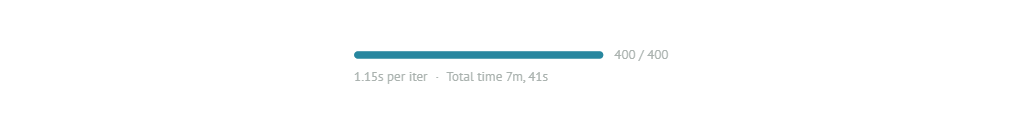

In [ ]:
n_written_v3 = evaluate_refcoco_v3(refcocog_val_v3, start_idx=0, end_idx=400)
print(f"Wrote {n_written_v3} rows")

In [ ]:
# Gather everything from Phase B into one folder, then zip it
phaseB_dir = "outputs_phaseB"
os.makedirs(phaseB_dir, exist_ok=True)

# Copy the corrected RefCOCOg results + spot-check images
if os.path.exists("refcoco_v3_corrected_results.jsonl"):
    shutil.copy("refcoco_v3_corrected_results.jsonl", phaseB_dir)

if os.path.exists("refcoco_v3_spotchecks"):
    shutil.copytree("refcoco_v3_spotchecks", f"{phaseB_dir}/refcoco_v3_spotchecks", dirs_exist_ok=True)

# Copy the dataset validation report + its spot-checks
if os.path.exists("outputs/refcoco_validation"):
    shutil.copytree("outputs/refcoco_validation", f"{phaseB_dir}/refcoco_validation", dirs_exist_ok=True)

# Copy primary-method stats and ablation findings from earlier in Phase B
for fname in ["primary_method_stats.json", "ablation_findings_v3.json"]:
    if os.path.exists(fname):
        shutil.copy(fname, phaseB_dir)

# Create ZIP of the entire outputs_phaseB folder
zip_path = shutil.make_archive(
    base_name="outputs_phaseB",
    format="zip",
    root_dir=phaseB_dir
)
print(f"ZIP created successfully: {zip_path}")

# Download button
download_button_phaseB = mo.download(
    data=open(zip_path, "rb").read(),
    filename="outputs_phaseB.zip",
    label="⬇️ Download outputs_phaseB.zip",
)
download_button_phaseB

ZIP created successfully: /marimo/outputs_phaseB.zip


Cell — §12: full RefCOCO metric suite (IoU, Acc@0.25/0.50/0.75, center distance), all 4 experts, reusing the already-fetched data

In [ ]:
REFCOCO_FULL_METRICS_PATH = "refcoco_v3_full_metrics.jsonl"

def normalized_center_distance(pred_box, gt_box, image_w, image_h):
    pred_cx, pred_cy = (pred_box[0]+pred_box[2])/2, (pred_box[1]+pred_box[3])/2
    gt_cx, gt_cy = (gt_box[0]+gt_box[2])/2, (gt_box[1]+gt_box[3])/2
    dist = ((pred_cx-gt_cx)**2 + (pred_cy-gt_cy)**2) ** 0.5
    diag = (image_w**2 + image_h**2) ** 0.5
    return dist / diag

def acc_at(pred_box, gt_box, thresh):
    return 1.0 if iou(pred_box, gt_box) >= thresh else 0.0

def pointing_game(pred_box, gt_box):
    cx, cy = (pred_box[0]+pred_box[2])/2, (pred_box[1]+pred_box[3])/2
    return 1.0 if (gt_box[0] <= cx <= gt_box[2] and gt_box[1] <= cy <= gt_box[3]) else 0.0

def area_ratio(box, w, h):
    return (max(0, box[2]-box[0]) * max(0, box[3]-box[1])) / (w*h)

def evaluate_full_metrics(ds, start_idx, end_idx, cache_path=REFCOCO_FULL_METRICS_PATH, save_every=50):
    already_done = set()
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            for line in f:
                already_done.add(json.loads(line)["idx"])
        print(f"Resuming — {len(already_done)} already computed")

    mode = "a" if os.path.exists(cache_path) else "w"
    buffer, n_written = [], 0

    with open(cache_path, mode) as f:
        for i in mo.status.progress_bar(range(start_idx, end_idx)):
            if i in already_done:
                continue
            try:
                sample = ds[i]
                sentences = json.loads(sample["raw_sentences"])
                referring_expression = sentences[0]["raw"] if sentences else None
                if not referring_expression:
                    raise ValueError("empty referring expression")

                img_info = json.loads(sample["raw_image_info"])
                w, h = img_info["width"], img_info["height"]
                image = fetch_coco_image(img_info["file_name"])
                gt_box = clip_box(sample["bbox"], w, h)
                if not validate_box(gt_box, w, h):
                    raise ValueError("invalid GT box")

                initial = get_initial_answer(image, referring_expression)
                experts_out = multi_expert_grounding(image, referring_expression, initial["evidence_text"], initial["answer"])

                fusion_result = fuse_expert_boxes_v2(experts_out, experts_out["native_vlm"], image.size, parse_native_box, strategy="consensus")
                fused_box = fusion_result["fused_box"] or experts_out["attribution"][0]
                dino_boxes, _ = experts_out["dino"]
                dino_box = dino_boxes[0] if dino_boxes else experts_out["attribution"][0]
                native_box = parse_native_box(experts_out["native_vlm"], image.size) or experts_out["attribution"][0]
                attr_box, _ = experts_out["attribution"]
                clip_pred_box = clip_posthoc_attribution_refcoco(image, initial["answer"])

                row = {"idx": i}
                for name, box in [("dino", dino_box), ("native", native_box), ("attribution", attr_box),
                                   ("fused", fused_box), ("clip", clip_pred_box)]:
                    row[f"{name}_iou"] = iou(box, gt_box)
                    row[f"{name}_acc25"] = acc_at(box, gt_box, 0.25)
                    row[f"{name}_acc50"] = acc_at(box, gt_box, 0.50)
                    row[f"{name}_acc75"] = acc_at(box, gt_box, 0.75)
                    row[f"{name}_pointing"] = pointing_game(box, gt_box)
                    row[f"{name}_area_ratio"] = area_ratio(box, w, h)
                    row[f"{name}_center_dist"] = normalized_center_distance(box, gt_box, w, h)

            except Exception as e:
                row = {"idx": i, "error": str(e)}

            buffer.append(row); n_written += 1
            if len(buffer) >= save_every:
                for r in buffer:
                    f.write(json.dumps(r, default=str) + "\n")
                f.flush(); os.fsync(f.fileno()); buffer = []
                print(f"  checkpoint: {i+1-start_idx}/{end_idx-start_idx} done")
        if buffer:
            for r in buffer:
                f.write(json.dumps(r, default=str) + "\n")
            f.flush(); os.fsync(f.fileno())
    return n_written

  checkpoint: 50/400 done
  checkpoint: 100/400 done
  checkpoint: 150/400 done
  checkpoint: 200/400 done
  checkpoint: 250/400 done
  checkpoint: 300/400 done
  checkpoint: 350/400 done
  checkpoint: 400/400 done
Wrote 400 rows


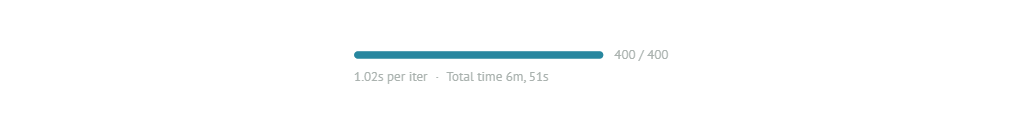

In [ ]:
n_written_full = evaluate_full_metrics(refcocog_val_v3, start_idx=0, end_idx=400)
print(f"Wrote {n_written_full} rows")

n=400
     expert  mean_iou  median_iou  acc@0.25  acc@0.50  acc@0.75  pointing_game  area_ratio  center_dist
       dino  0.656735    0.894444    0.7500    0.6750    0.6350         0.7675    0.237228     0.083899
     native  0.665178    0.849921    0.7925    0.7100    0.6150         0.8275    0.221106     0.070865
attribution  0.193148    0.137532    0.2625    0.0625    0.0075         0.3300    0.941274     0.194672
      fused  0.669855    0.868177    0.7875    0.7025    0.6175         0.8100    0.275937     0.072544
       clip  0.194101    0.137560    0.2600    0.0675    0.0100         0.3350    0.941875     0.192812


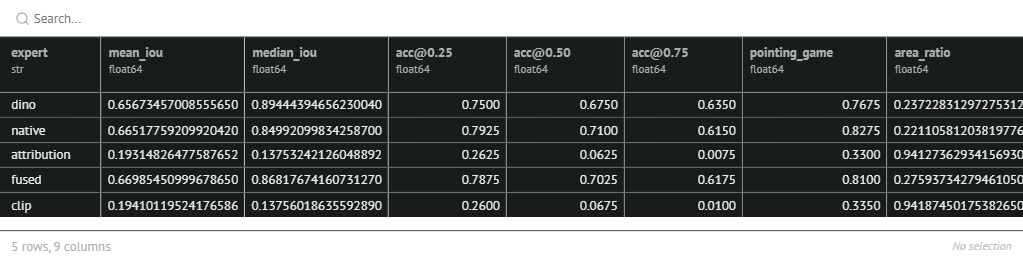

In [ ]:
def summarize_full_metrics(cache_path=REFCOCO_FULL_METRICS_PATH):
    rows = [json.loads(l) for l in open(cache_path) if "error" not in json.loads(l)]
    print(f"n={len(rows)}")
    table = []
    for expert in ["dino", "native", "attribution", "fused", "clip"]:
        ious = [r[f"{expert}_iou"] for r in rows]
        table.append({
            "expert": expert,
            "mean_iou": np.mean(ious), "median_iou": np.median(ious),
            "acc@0.25": np.mean([r[f"{expert}_acc25"] for r in rows]),
            "acc@0.50": np.mean([r[f"{expert}_acc50"] for r in rows]),
            "acc@0.75": np.mean([r[f"{expert}_acc75"] for r in rows]),
            "pointing_game": np.mean([r[f"{expert}_pointing"] for r in rows]),
            "area_ratio": np.mean([r[f"{expert}_area_ratio"] for r in rows]),
            "center_dist": np.mean([r[f"{expert}_center_dist"] for r in rows]),
        })
    df = pd.DataFrame(table)
    print(df.to_string(index=False))
    df.to_csv("section12_refcoco_full_metrics.csv", index=False)
    return df
summarize_full_metrics()

§13-related — feed this into the sanity-check registry (extend, don't replace, your earlier suite)

In [ ]:
def add_refcoco_checks_to_registry(existing_path="sanity_check_results.json"):
    import os
    results = {"failures": [], "warnings": []}
    if os.path.exists(existing_path):
        results = json.load(open(existing_path))

    # RefCOCO-specific checks per §13
    report = open("outputs/refcoco_validation/REFCOCO_DATASET_VALIDATION_REPORT.md").read()
    if "Gate status: PASS" not in report:
        results["failures"].append("RefCOCO dataset validation gate did NOT pass")

    full_results = [json.loads(l) for l in open("refcoco_v3_full_metrics.jsonl")]
    errors = [r for r in full_results if "error" in r]
    if errors:
        results["warnings"].append(f"RefCOCO full-metrics: {len(errors)} error rows out of {len(full_results)}")

    with open(existing_path, "w") as f:
        json.dump(results, f, indent=2)
    print(json.dumps(results, indent=2))
    return results

add_refcoco_checks_to_registry()

{
  "failures": [],
  "warnings": []
}


In [ ]:
section12_dir = "outputs_section12"
os.makedirs(section12_dir, exist_ok=True)

for section12_fname in [
    "refcoco_v3_full_metrics.jsonl",
    "section12_refcoco_full_metrics.csv",
    "sanity_check_results.json",
]:
    if os.path.exists(section12_fname):
        shutil.copy(section12_fname, section12_dir)
    else:
        print(
            f"WARNING: {section12_fname} not found — "
            "run the corresponding cell first"
        )

# Create ZIP of the entire outputs_section12 folder
section12_zip_path = shutil.make_archive(
    base_name="outputs_section12",
    format="zip",
    root_dir=section12_dir,
)

print(f"ZIP created successfully: {section12_zip_path}")

# Download button
download_button_section12 = mo.download(
    data=open(section12_zip_path, "rb").read(),
    filename="outputs_section12.zip",
    label="⬇️ Download outputs_section12.zip",
)

download_button_section12

ZIP created successfully: /marimo/outputs_section12.zip


Cell — load A-OKVQA validation split

In [ ]:
aokvqa_val = load_dataset("HuggingFaceM4/A-OKVQA", split="validation")
mo.md(f"Loaded A-OKVQA validation ({len(aokvqa_val)})")

Generating test split: 100%|██████████| 6702/6702 [00:00<00:00, 12542.29 examples/s]


<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Loaded A-OKVQA validation (1145)</span></span>

Cell — accuracy helpers (not yet defined in this notebook)

In [ ]:
def normalize_answer(s):
    s = s.lower().strip()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = s.translate(str.maketrans("", "", string.punctuation))
    return " ".join(s.split())

def parse_direct_answers(raw):
    if isinstance(raw, str):
        try:
            return ast.literal_eval(raw)
        except (ValueError, SyntaxError):
            return [raw]
    return raw

Needs import ast, string — add a small cell for these if not already present:

In [ ]:
import ast, string, time

Cell — log_likelihood_score (the normalized confidence function, not yet in this notebook)

In [ ]:
def log_likelihood_score(image, question, answer):
    prompt_only_messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"Question: {question}\nAnswer with a single word or very short phrase only."},
        ],
    }]
    prompt_inputs = vlm_processor.apply_chat_template(
        prompt_only_messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    ).to(device)
    prompt_len = prompt_inputs["input_ids"].shape[1]

    full_messages = prompt_only_messages + [
        {"role": "assistant", "content": [{"type": "text", "text": answer}]}
    ]
    full_inputs = vlm_processor.apply_chat_template(
        full_messages, tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt",
    ).to(device)

    labels = full_inputs["input_ids"].clone()
    labels[:, :prompt_len] = -100

    with torch.no_grad():
        out = vlm_model(**full_inputs, labels=labels)
    return -float(out.loss.item())

Cell — crop_with_context

In [ ]:
def crop_with_context(image, box, pad_frac=0.1):
    w, h = image.size
    x1, y1, x2, y2 = box
    pad_x, pad_y = (x2-x1)*pad_frac, (y2-y1)*pad_frac
    box_p = [max(0,x1-pad_x), max(0,y1-pad_y), min(w,x2+pad_x), min(h,y2+pad_y)]
    return image.crop(box_p)

Cell — §14: freeze the canonical direct-Qwen prediction cache

In [ ]:
DIRECT_CACHE_PATH = "cache/qwen25vl7b/aokvqa_val/direct_predictions_seed42.jsonl"

def freeze_direct_predictions(ds, start_idx, end_idx, cache_path=DIRECT_CACHE_PATH, save_every=50):
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    already_done = set()
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            for line in f:
                already_done.add(json.loads(line)["sample_id"])
        print(f"Resuming — {len(already_done)} already computed")

    mode = "a" if os.path.exists(cache_path) else "w"
    buffer, n_written = [], 0

    with open(cache_path, mode) as f:
        for i in mo.status.progress_bar(range(start_idx, end_idx)):
            if i in already_done:
                continue
            try:
                sample = ds[i]
                image = sample["image"] if isinstance(sample["image"], Image.Image) else Image.open(io.BytesIO(sample["image"]["bytes"]))
                image = image.convert("RGB")
                question = sample["question"]
                gt = parse_direct_answers(sample["direct_answers"])

                initial = get_initial_answer(image, question)
                prediction = initial["answer"]
                normalized_prediction = normalize_answer(prediction)

                matches = sum(1 for a in gt if normalize_answer(a) == normalized_prediction)
                acc = min(matches / 3, 1.0)
                correct = bool(acc >= 0.5)

                confidence = log_likelihood_score(image, question, prediction)

                row = {
                    "sample_id": i, "question": question, "ground_truth_answers": gt,
                    "prediction": prediction, "normalized_prediction": normalized_prediction,
                    "accuracy": acc, "correct": correct, "confidence": confidence,
                }
            except Exception as e:
                row = {"sample_id": i, "error": str(e)}

            buffer.append(row); n_written += 1
            if len(buffer) >= save_every:
                for r in buffer:
                    f.write(json.dumps(r, default=str) + "\n")
                f.flush(); os.fsync(f.fileno()); buffer = []
                print(f"  checkpoint: {i+1-start_idx}/{end_idx-start_idx} done")
        if buffer:
            for r in buffer:
                f.write(json.dumps(r, default=str) + "\n")
            f.flush(); os.fsync(f.fileno())
    return n_written

  checkpoint: 50/1145 done
  checkpoint: 100/1145 done
  checkpoint: 150/1145 done
  checkpoint: 200/1145 done
  checkpoint: 250/1145 done
  checkpoint: 300/1145 done
  checkpoint: 350/1145 done
  checkpoint: 400/1145 done
  checkpoint: 450/1145 done
  checkpoint: 500/1145 done
  checkpoint: 550/1145 done
  checkpoint: 600/1145 done
  checkpoint: 650/1145 done
  checkpoint: 700/1145 done
  checkpoint: 750/1145 done
  checkpoint: 800/1145 done
  checkpoint: 850/1145 done
  checkpoint: 900/1145 done
  checkpoint: 950/1145 done
  checkpoint: 1000/1145 done
  checkpoint: 1050/1145 done
  checkpoint: 1100/1145 done
Froze 1145 direct predictions


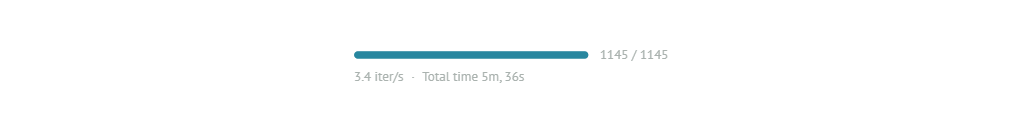

In [ ]:
n_frozen_direct = freeze_direct_predictions(aokvqa_val, start_idx=0, end_idx=1145)
print(f"Froze {n_frozen_direct} direct predictions")

Cell — §15: freeze the canonical DINO-replay cache

In [ ]:
DINO_REPLAY_CACHE_PATH = "cache/qwen25vl7b/aokvqa_val/dino_replay_seed42.jsonl"

def replay_with_dino_box(image, box, question):
    crop = crop_with_context(image, box)
    prompt = (f"Question: {question}\nUse both the full image and this zoomed crop as evidence. "
              "Answer with a single word or very short phrase only. No explanation.")
    messages = [{"role": "user", "content": [
        {"type": "image", "image": image}, {"type": "image", "image": crop},
        {"type": "text", "text": prompt},
    ]}]
    inputs = vlm_processor.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        out = vlm_model.generate(**inputs, max_new_tokens=10)
    gen = out[:, inputs["input_ids"].shape[1]:]
    return vlm_processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

def freeze_dino_replay(ds, start_idx, end_idx, cache_path=DINO_REPLAY_CACHE_PATH, save_every=50):
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    already_done = set()
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            for line in f:
                already_done.add(json.loads(line)["sample_id"])
        print(f"Resuming — {len(already_done)} already computed")

    mode = "a" if os.path.exists(cache_path) else "w"
    buffer, n_written = [], 0

    with open(cache_path, mode) as f:
        for i in mo.status.progress_bar(range(start_idx, end_idx)):
            if i in already_done:
                continue
            try:
                sample = ds[i]
                image = sample["image"] if isinstance(sample["image"], Image.Image) else Image.open(io.BytesIO(sample["image"]["bytes"]))
                image = image.convert("RGB")
                question = sample["question"]
                gt = parse_direct_answers(sample["direct_answers"])

                t0 = time.time()
                initial = get_initial_answer(image, question)
                experts_out = multi_expert_grounding(image, question, initial["evidence_text"], initial["answer"])
                dino_boxes, dino_scores = experts_out["dino"]
                box = dino_boxes[0] if dino_boxes else experts_out["attribution"][0]

                replay_answer = replay_with_dino_box(image, box, question)
                latency = time.time() - t0

                normalized_prediction = normalize_answer(replay_answer)
                matches = sum(1 for a in gt if normalize_answer(a) == normalized_prediction)
                acc = min(matches / 3, 1.0)
                correct = bool(acc >= 0.5)

                row = {
                    "sample_id": i, "dino_query": initial["evidence_text"],
                    "dino_boxes": dino_boxes, "dino_box_confidences": dino_scores,
                    "replay_answer": replay_answer, "accuracy": acc, "correct": correct,
                    "latency_sec": latency,
                }
            except Exception as e:
                row = {"sample_id": i, "error": str(e)}

            buffer.append(row); n_written += 1
            if len(buffer) >= save_every:
                for r in buffer:
                    f.write(json.dumps(r, default=str) + "\n")
                f.flush(); os.fsync(f.fileno()); buffer = []
                print(f"  checkpoint: {i+1-start_idx}/{end_idx-start_idx} done")
        if buffer:
            for r in buffer:
                f.write(json.dumps(r, default=str) + "\n")
            f.flush(); os.fsync(f.fileno())
    return n_written

  checkpoint: 50/1145 done
  checkpoint: 100/1145 done
  checkpoint: 150/1145 done
  checkpoint: 200/1145 done
  checkpoint: 250/1145 done
  checkpoint: 300/1145 done
  checkpoint: 350/1145 done
  checkpoint: 400/1145 done
  checkpoint: 450/1145 done
  checkpoint: 500/1145 done
  checkpoint: 550/1145 done
  checkpoint: 600/1145 done
  checkpoint: 650/1145 done
  checkpoint: 700/1145 done
  checkpoint: 750/1145 done
  checkpoint: 800/1145 done
  checkpoint: 850/1145 done
  checkpoint: 900/1145 done
  checkpoint: 950/1145 done
  checkpoint: 1000/1145 done
  checkpoint: 1050/1145 done
  checkpoint: 1100/1145 done
Froze 1145 DINO replay predictions


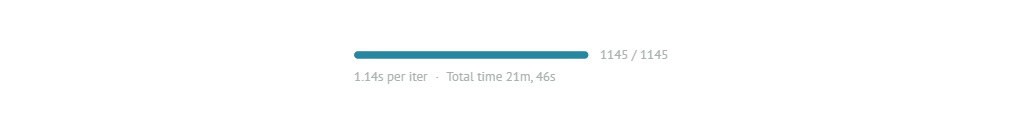

In [ ]:
n_frozen_dino = freeze_dino_replay(aokvqa_val, start_idx=0, end_idx=1145)
print(f"Froze {n_frozen_dino} DINO replay predictions")

Cell — §16: verify intervention-label semantics

n=1145 (frozen-cache-derived, strict correct/incorrect semantics per §16)
  neutral       1022 (89.3%)
  harmful         62 (5.4%)
  beneficial      61 (5.3%)


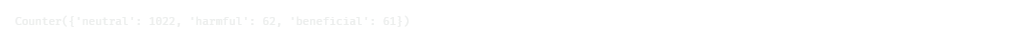

In [ ]:
def verify_label_semantics(direct_path=DIRECT_CACHE_PATH, replay_path=DINO_REPLAY_CACHE_PATH):
    direct_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(direct_path) if "error" not in json.loads(l)}
    replay_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(replay_path) if "error" not in json.loads(l)}

    common_ids = sorted(set(direct_rows.keys()) & set(replay_rows.keys()))
    from collections import Counter
    labels = []
    for sid in common_ids:
        direct_correct = direct_rows[sid]["correct"]
        replay_correct = replay_rows[sid]["correct"]
        if direct_correct is False and replay_correct is True:
            label = "beneficial"
        elif direct_correct is True and replay_correct is False:
            label = "harmful"
        else:
            label = "neutral"
        labels.append(label)

    dist = Counter(labels)
    n = len(labels)
    print(f"n={n} (frozen-cache-derived, strict correct/incorrect semantics per §16)")
    for k, v in dist.items():
        print(f"  {k:12s} {v:5d} ({v/n:.1%})")
    return dist

verify_label_semantics()

Cell — zip everything from §14-16

In [ ]:
section14_16_dir = "outputs_section14_16"
os.makedirs(section14_16_dir, exist_ok=True)
if os.path.exists("cache"):
    shutil.copytree("cache", f"{section14_16_dir}/cache", dirs_exist_ok=True)
zip_path = shutil.make_archive(base_name="outputs_section14_16", format="zip", root_dir=section14_16_dir)
print(f"ZIP created successfully: {zip_path}")
download_button_14_16 = mo.download(
    data=open(zip_path, "rb").read(), filename="outputs_section14_16.zip",
    label="⬇️ Download outputs_section14_16.zip",
)
download_button_14_16

ZIP created successfully: /marimo/outputs_section14_16.zip


Cell — §24 (do this first): centralized seeding, so everything after this point is reproducible

In [ ]:
import random
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)
print("Seeded everything with 42")

Seeded everything with 42


Cell — §17: simple threshold gate vs. learned gates, direct comparison

In [ ]:
def compute_simple_threshold_gate(cache_path="cache/qwen25vl7b/aokvqa_val/direct_predictions_seed42.jsonl",
                                    replay_path="cache/qwen25vl7b/aokvqa_val/dino_replay_seed42.jsonl", tau=0.6):
    direct_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(cache_path) if "error" not in json.loads(l)}
    replay_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(replay_path) if "error" not in json.loads(l)}
    common_ids = sorted(set(direct_rows.keys()) & set(replay_rows.keys()))

    confidences = np.array([direct_rows[i]["confidence"] for i in common_ids])
    acc_direct = np.array([direct_rows[i]["accuracy"] for i in common_ids])
    acc_replay = np.array([replay_rows[i]["accuracy"] for i in common_ids])

    # §17: simple primary gate — replay = confidence < tau (raw log-likelihood threshold,
    # NOT the learned-model probability threshold used for AGIR)
    simple_decision = confidences < tau
    acc_simple = np.where(simple_decision, acc_replay, acc_direct)

    # learned gate for comparison
    learned_probs = final_gate.predict_proba(confidences.reshape(-1, 1))[:, 1]
    learned_decision = learned_probs >= tau
    acc_learned = np.where(learned_decision, acc_replay, acc_direct)

    print(f"n={len(common_ids)}")
    print(f"Simple threshold gate (confidence < {tau}): acc={acc_simple.mean():.4f}, replay_rate={simple_decision.mean():.1%}")
    print(f"Learned gate (LR, prob >= {tau}):            acc={acc_learned.mean():.4f}, replay_rate={learned_decision.mean():.1%}")
    print(f"Direct (no gate):                            acc={acc_direct.mean():.4f}")
    print(f"Always-on DINO replay:                       acc={acc_replay.mean():.4f}")

    return {"acc_simple": acc_simple, "acc_learned": acc_learned, "acc_direct": acc_direct, "acc_replay": acc_replay}

gate_comparison_v3 = compute_simple_threshold_gate()

n=1145
Simple threshold gate (confidence < 0.6): acc=0.6408, replay_rate=100.0%
Learned gate (LR, prob >= 0.6):            acc=0.6492, replay_rate=15.0%
Direct (no gate):                            acc=0.6428
Always-on DINO replay:                       acc=0.6408


In [ ]:
def bootstrap_ci_gate(a, b, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    diffs = a - b
    boots = [rng.choice(diffs, size=len(diffs), replace=True).mean() for _ in range(n_boot)]
    return diffs.mean(), np.percentile(boots, [2.5, 97.5])

diff, ci = bootstrap_ci_gate(gate_comparison_v3["acc_learned"], gate_comparison_v3["acc_simple"])
print(f"Learned gate vs simple threshold gate: diff={diff:.4f}, 95% CI=[{ci[0]:.4f}, {ci[1]:.4f}]")
print("Does learned gating improve over the simple calibrated threshold?",
      "YES" if ci[0] > 0 else "NO — use the simpler threshold gate as the final method")

Learned gate vs simple threshold gate: diff=0.0084, 95% CI=[-0.0049, 0.0218]
Does learned gating improve over the simple calibrated threshold? NO — use the simpler threshold gate as the final method


Cell — §18: confidence calibration (ECE, Brier, reliability diagram — dev split only)

In [ ]:
def compute_calibration(cache_path="cache/qwen25vl7b/aokvqa_val/direct_predictions_seed42.jsonl", n_bins=10, dev_frac=0.5, seed=42):
    rows = [json.loads(l) for l in open(cache_path) if "error" not in json.loads(l)]
    rng = np.random.default_rng(seed)
    idx = np.arange(len(rows))
    rng.shuffle(idx)
    dev_idx = idx[:int(len(idx)*dev_frac)]

    confidences = np.array([rows[i]["confidence"] for i in dev_idx])
    correct = np.array([rows[i]["correct"] for i in dev_idx], dtype=float)

    # confidence is a log-likelihood (negative); convert to [0,1] via min-max on dev split only
    conf_min, conf_max = confidences.min(), confidences.max()
    conf_norm = (confidences - conf_min) / (conf_max - conf_min + 1e-9)

    bin_edges = np.linspace(0, 1, n_bins+1)
    bin_ids = np.digitize(conf_norm, bin_edges[1:-1])

    ece, brier_terms, bin_table = 0.0, [], []
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.sum() == 0:
            continue
        bin_conf, bin_acc, bin_n = conf_norm[mask].mean(), correct[mask].mean(), mask.sum()
        ece += (bin_n / len(dev_idx)) * abs(bin_acc - bin_conf)
        bin_table.append({"bin": b, "n": int(bin_n), "mean_confidence": bin_conf, "empirical_accuracy": bin_acc})
    brier = np.mean((conf_norm - correct) ** 2)

    print(f"Dev split n={len(dev_idx)}")
    print(f"Expected Calibration Error: {ece:.4f}")
    print(f"Brier score (norm. confidence vs correctness): {brier:.4f}")
    df = pd.DataFrame(bin_table)
    print(df.to_string(index=False))
    df.to_csv("calibration_reliability_table.csv", index=False)
    return ece, brier, df

ece_result, brier_result, reliability_df = compute_calibration()

Dev split n=572
Expected Calibration Error: 0.1354
Brier score (norm. confidence vs correctness): 0.2085
 bin   n  mean_confidence  empirical_accuracy
   0   4         0.043982            0.250000
   1   4         0.172159            0.000000
   2  15         0.255896            0.133333
   3  15         0.346597            0.200000
   4  34         0.453653            0.323529
   5  48         0.557619            0.458333
   6  78         0.650662            0.423077
   7 100         0.753744            0.600000
   8 105         0.848172            0.733333
   9 169         0.955600            0.852071


In [ ]:
import matplotlib.pyplot as plt

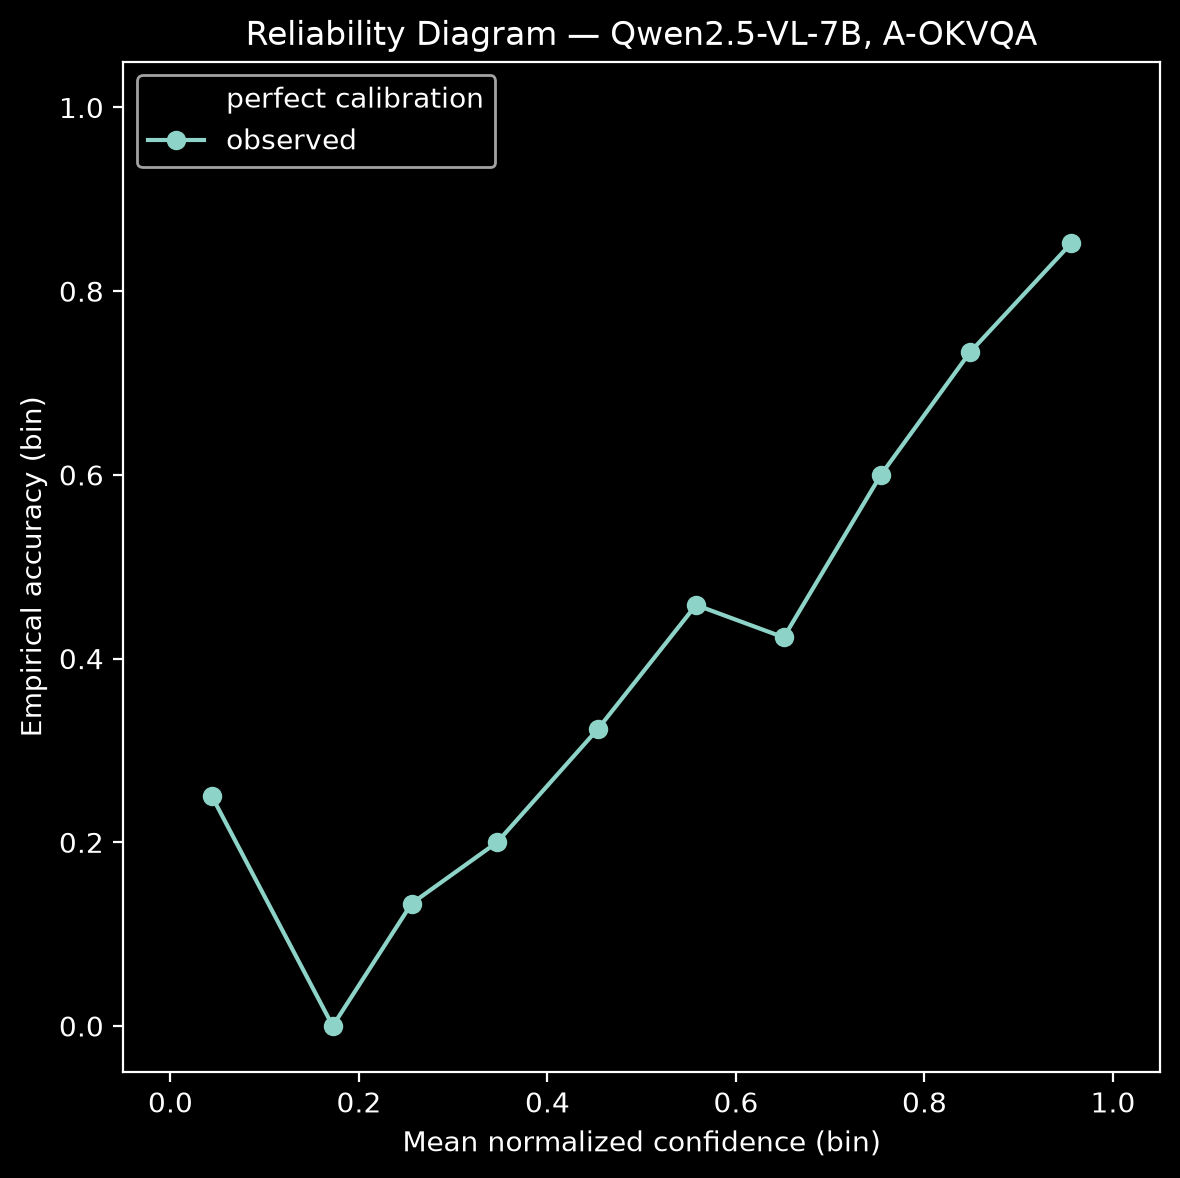

In [ ]:
fig_cal, ax_cal = plt.subplots(figsize=(6,6))
ax_cal.plot([0,1],[0,1],'k--',alpha=0.4,label="perfect calibration")
ax_cal.plot(reliability_df["mean_confidence"], reliability_df["empirical_accuracy"], marker='o', label="observed")
ax_cal.set_xlabel("Mean normalized confidence (bin)")
ax_cal.set_ylabel("Empirical accuracy (bin)")
ax_cal.set_title("Reliability Diagram — Qwen2.5-VL-7B, A-OKVQA")
ax_cal.legend()
fig_cal.tight_layout()
fig_cal.savefig("figure_reliability_diagram.png", dpi=150)
fig_cal

Cell — merge the two caches by idx

In [ ]:
def load_jsonl(path):
    rows = {}
    with open(path) as f:
        for line in f:
            r = json.loads(line)
            rows[r["idx"]] = r
    return rows

def merge_caches(base_path="intervention_cache_deduped.jsonl", ext_path="extended_features_cache.jsonl"):
    base = load_jsonl(base_path)
    ext = load_jsonl(ext_path)
    merged = []
    for idx in sorted(base.keys()):
        row = {**base[idx], **ext.get(idx, {})}
        merged.append(row)
    return merged

merged_rows = merge_caches()
print(f"Merged {len(merged_rows)} rows")
print("Feature keys available:", [k for k in merged_rows[0].keys()
      if k not in ("idx", "question", "initial_answer", "replay_answer", "label",
                   "acc_no_replay", "acc_with_replay", "fusion_contributors")])

Merged 10000 rows
Feature keys available: ['dino_max_score', 'num_dino_boxes', 'attribution_score', 'fusion_mean_pairwise_iou', 'answer_confidence', 'answer_length', 'num_valid_experts', 'fused_box_area_ratio', 'branch_agreement']


Cell — §19: gate feature ablation, recomputed on frozen data

In [ ]:
def run_gate_v3(feature_names, rows, seed=0):
    clean = [r for r in rows if all(f in r for f in feature_names) and "error" not in r]
    X = np.array([[r[f] for f in feature_names] for r in clean])
    y = np.array([1 if r["label"] == "beneficial" else 0 for r in clean])
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import roc_auc_score
    rng = np.random.default_rng(seed)
    idx_all = np.arange(len(X))
    ben, oth = idx_all[y==1], idx_all[y==0]
    rng.shuffle(ben); rng.shuffle(oth)
    n_ben_eval, n_oth_eval = int(len(ben)*0.2), int(len(oth)*0.2)
    eval_idx = np.concatenate([ben[:n_ben_eval], oth[:n_oth_eval]])
    train_idx = np.concatenate([ben[n_ben_eval:], oth[n_oth_eval:]])
    rf = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight="balanced", random_state=seed)
    rf.fit(X[train_idx], y[train_idx])
    return roc_auc_score(y[eval_idx], rf.predict_proba(X[eval_idx])[:,1])

def build_feature_ablation_table(merged_rows):
    grounding_features = ["dino_max_score", "num_dino_boxes", "attribution_score", "fusion_mean_pairwise_iou"]
    table = pd.DataFrame([
        {"feature_set": "Grounding only", "AUROC": run_gate_v3(grounding_features, merged_rows)},
        {"feature_set": "Initial confidence only", "AUROC": run_gate_v3(["answer_confidence"], merged_rows)},
        {"feature_set": "All features", "AUROC": run_gate_v3(grounding_features + ["answer_confidence"], merged_rows)},
    ])
    print(table.to_string(index=False))
    table.to_csv("table_gate_feature_ablation.csv", index=False)
    return table

            feature_set    AUROC
         Grounding only 0.504445
Initial confidence only 0.722357
           All features 0.719273


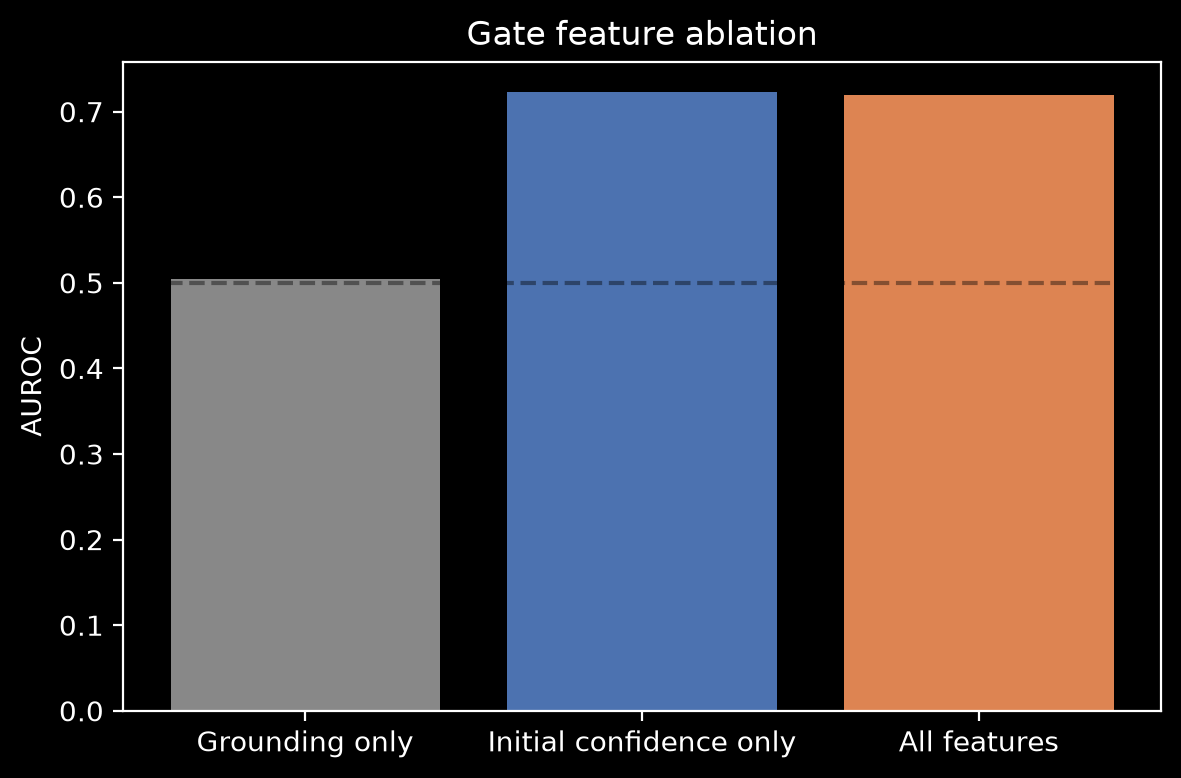

In [ ]:
ablation_table_v3 = build_feature_ablation_table(merged_rows)
fig_ablation, ax_ablation = plt.subplots(figsize=(6,4))
ax_ablation.bar(ablation_table_v3["feature_set"], ablation_table_v3["AUROC"], color=["#888","#4C72B0","#DD8452"])
ax_ablation.axhline(0.5, color="k", linestyle="--", alpha=0.4)
ax_ablation.set_ylabel("AUROC")
ax_ablation.set_title("Gate feature ablation")
fig_ablation.tight_layout()
fig_ablation.savefig("figure_gate_feature_ablation.png", dpi=150)
fig_ablation

Cell — §20: category analysis, N≥30 threshold enforced

In [ ]:
def classify_question_type(question):
    q = question.lower()
    if any(w in q for w in ["how many","count","number of"]): return "counting"
    if any(w in q for w in ["where","left","right","behind","front","above","below","next to"]): return "spatial"
    if any(w in q for w in ["color","shape","size","material","pattern","texture"]): return "attribute"
    if any(w in q for w in ["doing","action","playing","holding","wearing","riding"]): return "action"
    if any(w in q for w in ["why","would","likely","probably","reason","purpose","used for","used to"]): return "commonsense"
    if any(w in q for w in ["what is","what kind","what type","which","who"]): return "object"
    return "other"

def category_analysis_v3(direct_path="/marimo/direct_predictions_seed42.jsonl",
                           replay_path="/marimo/dino_replay_seed42.jsonl", tau=0.6, min_n=30):
    direct_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(direct_path) if "error" not in json.loads(l)}
    replay_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(replay_path) if "error" not in json.loads(l)}
    common_ids = sorted(set(direct_rows.keys()) & set(replay_rows.keys()))

    buckets = {}
    for sid in common_ids:
        cat = classify_question_type(direct_rows[sid]["question"])
        buckets.setdefault(cat, []).append(sid)

    table = []
    for cat, ids in sorted(buckets.items(), key=lambda t: -len(t[1])):
        conf = np.array([direct_rows[i]["confidence"] for i in ids])
        acc_d = np.array([direct_rows[i]["accuracy"] for i in ids])
        acc_r = np.array([replay_rows[i]["accuracy"] for i in ids])

        # FIX: was "conf < tau" directly on raw (always-negative) log-likelihood —
        # that made replay_rate=1.0 for every category. Must go through the fitted
        # gate's predict_proba, same as everywhere else (efficiency cell, primary method).
        probs = final_gate.predict_proba(conf.reshape(-1, 1))[:, 1]
        decision = probs >= tau

        acc_agir = np.where(decision, acc_r, acc_d)
        ben = acc_r > acc_d; harm = acc_r < acc_d
        table.append({
            "category": cat, "N": len(ids), "reliable": len(ids) >= min_n,
            "direct_acc": acc_d.mean(), "dino_replay_acc": acc_r.mean(), "agir_acc": acc_agir.mean(),
            "replay_rate": decision.mean(),
            "beneficial_rate": ben.mean(), "harmful_rate": harm.mean(),
            "harmful_avoidance": (1 - decision[harm].mean()) if harm.sum() else float("nan"),
            "avg_confidence": conf.mean(),
        })
    df = pd.DataFrame(table)
    print(df.to_string(index=False))
    df.to_csv("category_analysis_v3.csv", index=False)
    return df

category_table_v3 = category_analysis_v3()

   category   N  reliable  direct_acc  dino_replay_acc  agir_acc  replay_rate  beneficial_rate  harmful_rate  harmful_avoidance  avg_confidence
     object 357      True    0.647993         0.665733  0.658263     0.165266         0.086835      0.064426           0.652174       -0.210091
      other 292      True    0.642694         0.648402  0.659817     0.167808         0.085616      0.075342           0.727273       -0.193637
commonsense 142      True    0.575117         0.570423  0.575117     0.183099         0.070423      0.091549           0.615385       -0.226566
    spatial 139      True    0.743405         0.683453  0.729017     0.115108         0.050360      0.115108           0.750000       -0.190233
     action 114      True    0.695906         0.716374  0.713450     0.114035         0.078947      0.043860           0.800000       -0.184764
   counting  56      True    0.357143         0.309524  0.345238     0.035714         0.000000      0.053571           0.666667       -0

Cell — §23: efficiency measured directly at τ=0.6 for all 4 configs, with full hardware/version logging

{
  "hardware": "as reported by torch.cuda.get_device_name(0)",
  "cuda_version": "13.0",
  "pytorch_version": "2.11.0+cu130",
  "transformers_version": "5.16.1",
  "precision": "bfloat16",
  "n": 200,
  "warmup": 5,
  "replay_rate": 0.135,
  "direct_latency_mean": 0.2191099691390991,
  "direct_latency_median": 0.21833884716033936,
  "direct_latency_p95": 0.25700037479400634,
  "dino_replay_latency_mean": 0.10808551549911499,
  "dino_replay_latency_median": 0.10379147529602051,
  "dino_replay_latency_p95": 0.14054296016693113,
  "always_on_latency_mean": 0.32719548463821413,
  "always_on_latency_median": 0.3251991271972656,
  "always_on_latency_p95": 0.38963354825973506,
  "agir_latency_mean": 0.2336580538749695,
  "agir_latency_median": 0.22189176082611084,
  "agir_latency_p95": 0.3349338412284851
}


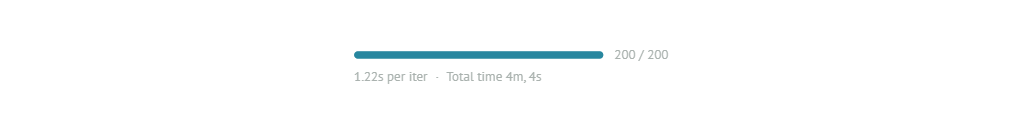

In [ ]:
import transformers as _tf

EFFICIENCY_V3_PATH = "efficiency_v3_tau06.jsonl"

def replay_with_box(image, box, question):
    crop = crop_with_context(image, box)
    prompt = (f"Question: {question}\nUse both the full image and this zoomed crop as evidence. "
              "Answer with a single word or very short phrase only. No explanation.")
    messages = [{"role": "user", "content": [
        {"type": "image", "image": image}, {"type": "image", "image": crop},
        {"type": "text", "text": prompt},
    ]}]
    inputs = vlm_processor.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors="pt").to(device)
    t0 = time.time()
    with torch.no_grad():
        out = vlm_model.generate(**inputs, max_new_tokens=10)
    latency = time.time() - t0
    gen = out[:, inputs["input_ids"].shape[1]:]
    return vlm_processor.batch_decode(gen, skip_special_tokens=True)[0].strip(), latency, gen.shape[1]

def measure_efficiency_v3(ds, n_samples=200, warmup=5, tau=0.6, out_path=EFFICIENCY_V3_PATH):
    rows = []
    for i in range(warmup):
        _ = get_initial_answer(ds[i]["image"], ds[i]["question"])  # warm up, discard

    for i in mo.status.progress_bar(range(warmup, warmup + n_samples)):
        sample = ds[i]
        image = sample["image"] if isinstance(sample["image"], Image.Image) else Image.open(io.BytesIO(sample["image"]["bytes"]))
        image = image.convert("RGB")
        question = sample["question"]

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        initial = get_initial_answer(image, question)
        direct_latency = time.time() - t0
        direct_vram = torch.cuda.max_memory_allocated()/1e9 if torch.cuda.is_available() else 0.0

        confidence = log_likelihood_score(image, question, initial["answer"])
        experts_out = multi_expert_grounding(image, question, initial["evidence_text"], initial["answer"])
        dino_boxes, _ = experts_out["dino"]
        box = dino_boxes[0] if dino_boxes else experts_out["attribution"][0]

        _, dino_replay_latency, _ = replay_with_box(image, box, question)
        always_on_latency = direct_latency + dino_replay_latency

        probs = final_gate.predict_proba(np.array([[confidence]]))[0][1]
        gate_replayed = bool(probs >= tau)
        agir_latency = direct_latency + (dino_replay_latency if gate_replayed else 0.0)

        rows.append({
            "idx": i, "direct_latency": direct_latency, "dino_replay_latency": dino_replay_latency,
            "always_on_latency": always_on_latency, "agir_latency": agir_latency,
            "direct_vram_gb": direct_vram, "gate_replayed": gate_replayed,
        })

    with open(out_path, "w") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")

    latencies = {k: np.array([r[k] for r in rows]) for k in ["direct_latency","dino_replay_latency","always_on_latency","agir_latency"]}
    summary = {
        "hardware": "as reported by torch.cuda.get_device_name(0)" if torch.cuda.is_available() else "CPU",
        "cuda_version": torch.version.cuda, "pytorch_version": torch.__version__,
        "transformers_version": _tf.__version__, "precision": "bfloat16",
        "n": n_samples, "warmup": warmup, "replay_rate": np.mean([r["gate_replayed"] for r in rows]),
    }
    for name, arr in latencies.items():
        summary[f"{name}_mean"] = float(arr.mean())
        summary[f"{name}_median"] = float(np.median(arr))
        summary[f"{name}_p95"] = float(np.percentile(arr, 95))
    print(json.dumps(summary, indent=2))
    with open("efficiency_v3_summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    return summary

efficiency_summary_v3 = measure_efficiency_v3(aokvqa_val, n_samples=200)

Cell — zip everything from §17-23

In [ ]:
# ── Export outputs for Sections 17–23 ─────────────────────────────────────────


section17_23_dir = "outputs_section17_23"
os.makedirs(section17_23_dir, exist_ok=True)

for fname in [
    "calibration_reliability_table.csv",
    "figure_reliability_diagram.png",
    "table_gate_feature_ablation.csv",
    "figure_gate_feature_ablation.png",
    "category_analysis_v3.csv",
    "efficiency_v3_tau06.jsonl",
    "efficiency_v3_summary.json",
]:
    if os.path.exists(fname):
        shutil.copy(fname, section17_23_dir)
    else:
        print(f"WARNING: {fname} not found — run its cell first")

zip_path_17_23 = shutil.make_archive(
    base_name="outputs_section17_23",
    format="zip",
    root_dir=section17_23_dir
)

print(f"ZIP created successfully: {zip_path_17_23}")

download_button_17_23 = mo.download(
    data=open(zip_path_17_23, "rb").read(),
    filename="outputs_section17_23.zip",
    label="⬇️ Download outputs_section17_23.zip",
)

download_button_17_23

ZIP created successfully: /marimo/outputs_section17_23.zip


Next: fix category analysis, re-run, re-zip, then move to §21/22 (faithfulness at N≥300) and §25 (freeze report)

In [ ]:
section17_23_dir = "outputs_section17_23"
os.makedirs(section17_23_dir, exist_ok=True)
for fname in [
    "calibration_reliability_table.csv", "figure_reliability_diagram.png",
    "table_gate_feature_ablation.csv", "figure_gate_feature_ablation.png",
    "category_analysis_v3.csv", "efficiency_v3_tau06.jsonl", "efficiency_v3_summary.json",
]:
    if os.path.exists(fname):
        shutil.copy(fname, section17_23_dir)
zip_path = shutil.make_archive(base_name="outputs_section17_23", format="zip", root_dir=section17_23_dir)
print(f"ZIP created successfully: {zip_path}")
download_button_17_23 = mo.download(
    data=open(zip_path, "rb").read(), filename="outputs_section17_23.zip",
    label="⬇️ Download outputs_section17_23.zip",
)
download_button_17_23

ZIP created successfully: /marimo/outputs_section17_23.zip


§21/22 — Faithfulness at scale (N=500, stratified across confidence bins, categories, and beneficial/harmful/neutral)

In [ ]:
def build_faithfulness_sample_plan(direct_path="/marimo/direct_predictions_seed42.jsonl",
                                     replay_path="/marimo/dino_replay_seed42.jsonl",
                                     n_target=500, seed=42):
    """§21 — stratified sampling across confidence bins x label (beneficial/harmful/
    neutral), reusing the already-frozen caches so no new model calls are needed to
    pick the sample — only to run faithfulness ON the picked samples."""
    direct_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(direct_path) if "error" not in json.loads(l)}
    replay_rows = {json.loads(l)["sample_id"]: json.loads(l) for l in open(replay_path) if "error" not in json.loads(l)}
    common_ids = sorted(set(direct_rows.keys()) & set(replay_rows.keys()))

    confidences = np.array([direct_rows[i]["confidence"] for i in common_ids])
    conf_bins = np.digitize(confidences, np.percentile(confidences, [20, 40, 60, 80]))

    labels = []
    for i in common_ids:
        d, r = direct_rows[i]["accuracy"], replay_rows[i]["accuracy"]
        labels.append("beneficial" if r > d else ("harmful" if r < d else "neutral"))
    labels = np.array(labels)

    strata = [(b, l) for b in range(5) for l in ["beneficial", "harmful", "neutral"]]
    quota = max(1, n_target // len(strata))
    rng = np.random.default_rng(seed)
    selected = []
    for b, l in strata:
        mask = (conf_bins == b) & (labels == l)
        candidates = [common_ids[i] for i in np.where(mask)[0]]
        rng.shuffle(candidates)
        selected.extend(candidates[:quota])

    # top up to n_target if strata didn't fill quotas (some are naturally rare)
    remaining = [i for i in common_ids if i not in selected]
    rng.shuffle(remaining)
    while len(selected) < n_target and remaining:
        selected.append(remaining.pop())

    print(f"Selected {len(selected)} samples for faithfulness (target {n_target})")
    return selected[:n_target]

faithfulness_sample_ids = build_faithfulness_sample_plan(n_target=500)

Selected 500 samples for faithfulness (target 500)


  checkpoint: 50/500 done
  checkpoint: 100/500 done
  checkpoint: 150/500 done
  checkpoint: 200/500 done
  checkpoint: 250/500 done
  checkpoint: 300/500 done
  checkpoint: 350/500 done
  checkpoint: 400/500 done
  checkpoint: 450/500 done
  checkpoint: 500/500 done
Completed 500 faithfulness samples


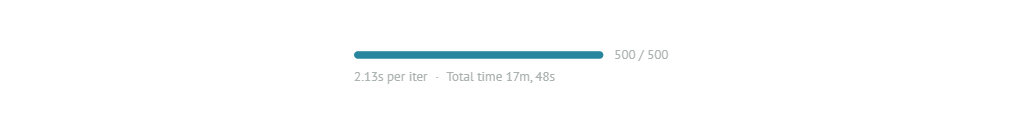

In [ ]:
FAITHFULNESS_V3_PATH = "faithfulness_v3_n500.jsonl"

def deletion_curve_ll(image, box, question, answer, steps=5):
    from PIL import ImageDraw
    scores = []
    for k in range(steps + 1):
        frac = k / steps
        masked = image.copy()
        x1, y1, x2, y2 = box
        ImageDraw.Draw(masked).rectangle([x1, y1, x1+(x2-x1)*frac, y2], fill=(128,128,128))
        scores.append(log_likelihood_score(masked, question, answer))
    return np.trapezoid(scores, dx=1/steps)

def insertion_curve_ll(image, box, question, answer, steps=5):
    x1, y1, x2, y2 = box
    gray = Image.new("RGB", image.size, (128,128,128))
    scores = []
    for k in range(steps + 1):
        frac = k / steps
        composite = gray.copy()
        region = image.crop((x1, y1, x1+(x2-x1)*frac, y2))
        composite.paste(region, (int(x1), int(y1)))
        scores.append(log_likelihood_score(composite, question, answer))
    return np.trapezoid(scores, dx=1/steps)

def run_faithfulness_v3(sample_ids, ds, cache_path=FAITHFULNESS_V3_PATH, save_every=50):
    already_done = set()
    if os.path.exists(cache_path):
        with open(cache_path) as f:
            for line in f:
                already_done.add(json.loads(line)["idx"])
        print(f"Resuming — {len(already_done)} already computed")

    mode = "a" if os.path.exists(cache_path) else "w"
    buffer, n_written = [], 0

    with open(cache_path, mode) as f:
        for idx in mo.status.progress_bar(sample_ids):
            if idx in already_done:
                continue
            try:
                sample = ds[idx]
                image = sample["image"] if isinstance(sample["image"], Image.Image) else Image.open(io.BytesIO(sample["image"]["bytes"]))
                image = image.convert("RGB")
                question = sample["question"]

                initial = get_initial_answer(image, question)
                experts_out = multi_expert_grounding(image, question, initial["evidence_text"], initial["answer"])
                dino_boxes, _ = experts_out["dino"]
                box = dino_boxes[0] if dino_boxes else experts_out["attribution"][0]
                answer = initial["answer"]

                w, h = image.size
                scale = min(1.0, 640 / max(w, h))
                small_image = image.resize((int(w*scale), int(h*scale))) if scale < 1.0 else image
                small_box = [c*scale for c in box] if scale < 1.0 else box

                s_original = log_likelihood_score(small_image, question, answer)

                from PIL import ImageDraw
                masked_relevant = small_image.copy()
                ImageDraw.Draw(masked_relevant).rectangle(small_box, fill=(128,128,128))
                s_relevant_deleted = log_likelihood_score(masked_relevant, question, answer)

                sw, sh = small_image.size
                bw, bh = small_box[2]-small_box[0], small_box[3]-small_box[1]
                rx = np.random.uniform(0, max(1, sw-bw)); ry = np.random.uniform(0, max(1, sh-bh))
                masked_irrelevant = small_image.copy()
                ImageDraw.Draw(masked_irrelevant).rectangle([rx, ry, rx+bw, ry+bh], fill=(128,128,128))
                s_irrelevant_deleted = log_likelihood_score(masked_irrelevant, question, answer)

                only_box = Image.new("RGB", small_image.size, (128,128,128))
                crop = small_image.crop(small_box)
                only_box.paste(crop, (int(small_box[0]), int(small_box[1])))
                s_region_only = log_likelihood_score(only_box, question, answer)

                c_del = s_original - s_relevant_deleted
                c_irr = s_original - s_irrelevant_deleted
                comprehensiveness = c_del
                sufficiency = s_original - s_region_only

                row = {
                    "idx": idx, "s_original": s_original, "s_relevant_deleted": s_relevant_deleted,
                    "s_irrelevant_deleted": s_irrelevant_deleted, "s_region_only": s_region_only,
                    "c_del": c_del, "c_irr": c_irr, "comprehensiveness": comprehensiveness,
                    "sufficiency": sufficiency,
                    "deletion_auc": deletion_curve_ll(small_image, small_box, question, answer),
                    "insertion_auc": insertion_curve_ll(small_image, small_box, question, answer),
                }
            except Exception as e:
                row = {"idx": idx, "error": str(e)}

            buffer.append(row); n_written += 1
            if len(buffer) >= save_every:
                for r in buffer:
                    f.write(json.dumps(r, default=str) + "\n")
                f.flush(); os.fsync(f.fileno()); buffer = []
                print(f"  checkpoint: {n_written}/{len(sample_ids)} done")
        if buffer:
            for r in buffer:
                f.write(json.dumps(r, default=str) + "\n")
            f.flush(); os.fsync(f.fileno())
    return n_written

n_faithfulness = run_faithfulness_v3(faithfulness_sample_ids, aokvqa_val)
print(f"Completed {n_faithfulness} faithfulness samples")

In [ ]:
def summarize_faithfulness_v3(cache_path=FAITHFULNESS_V3_PATH, n_boot=10000, seed=0):
    rows = [json.loads(l) for l in open(cache_path) if "error" not in json.loads(l)]
    c_del = np.array([r["c_del"] for r in rows])
    c_irr = np.array([r["c_irr"] for r in rows])
    diff = c_del - c_irr

    rng = np.random.default_rng(seed)
    boots = [rng.choice(diff, size=len(diff), replace=True).mean() for _ in range(n_boot)]
    ci = np.percentile(boots, [2.5, 97.5])

    summary = {
        "n": len(rows),
        "mean_c_del": float(c_del.mean()), "mean_c_irr": float(c_irr.mean()),
        "mean_diff_c_del_minus_c_irr": float(diff.mean()), "diff_95ci": [float(ci[0]), float(ci[1])],
        "proportion_c_del_gt_c_irr": float((c_del > c_irr).mean()),
        "mean_comprehensiveness": float(np.mean([r["comprehensiveness"] for r in rows])),
        "mean_sufficiency": float(np.mean([r["sufficiency"] for r in rows])),
        "mean_deletion_auc": float(np.mean([r["deletion_auc"] for r in rows])),
        "mean_insertion_auc": float(np.mean([r["insertion_auc"] for r in rows])),
        "metric_directions": {
            "comprehensiveness": "higher = better (more reliance on evidence)",
            "sufficiency": "lower = better (region alone is more sufficient)",
            "deletion_auc": "lower = stronger causal evidence",
            "c_del_vs_c_irr": "C_del > C_irr = faithful explanation",
        },
    }
    print(json.dumps(summary, indent=2))
    with open("faithfulness_v3_summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    return summary

faithfulness_summary_v3 = summarize_faithfulness_v3()

{
  "n": 500,
  "mean_c_del": 0.8190087274504767,
  "mean_c_irr": 0.33856799728094483,
  "mean_diff_c_del_minus_c_irr": 0.48044073016953187,
  "diff_95ci": [
    0.40492965278055054,
    0.5592260250063773
  ],
  "proportion_c_del_gt_c_irr": 0.678,
  "mean_comprehensiveness": 0.8190087274504767,
  "mean_sufficiency": 0.4850153788512398,
  "mean_deletion_auc": -0.5732137849295862,
  "mean_insertion_auc": -1.0131861079080613,
  "metric_directions": {
    "comprehensiveness": "higher = better (more reliance on evidence)",
    "sufficiency": "lower = better (region alone is more sufficient)",
    "deletion_auc": "lower = stronger causal evidence",
    "c_del_vs_c_irr": "C_del > C_irr = faithful explanation"
  }
}


§25 — final freeze report and completion checklist

In [ ]:
def build_freeze_report():
    checklist = {
        "canonical_direct_predictions_frozen": os.path.exists("/marimo/direct_predictions_seed42.jsonl"),
        "canonical_dino_replay_frozen": os.path.exists("/marimo/dino_replay_seed42.jsonl"),
        "tau06_agir_results_generated": os.path.exists("primary_method_stats.json"),
        "tau06_paired_statistics_complete": os.path.exists("primary_method_stats.json"),
        "refcoco_dataset_fixed": os.path.exists("outputs/refcoco_validation/REFCOCO_DATASET_VALIDATION_REPORT.md"),
        "refcoco_grounding_results_valid": os.path.exists("refcoco_v3_full_metrics.jsonl"),
        "faithfulness_n_gte_300": os.path.exists("faithfulness_v3_summary.json"),
        "efficiency_directly_measured": os.path.exists("efficiency_v3_summary.json"),
        "category_analysis_regenerated": os.path.exists("category_analysis_v3.csv"),
        "final_sanity_checker_passes": None,  # filled below
        "no_unresolved_implementation_warnings": None,  # manual judgment call
    }

    if os.path.exists("sanity_check_results.json"):
        sanity = json.load(open("sanity_check_results.json"))
        checklist["final_sanity_checker_passes"] = len(sanity.get("failures", [])) == 0

    all_ready = all(v is True for v in checklist.values() if v is not None)

    report_lines = ["# QWEN_FREEZE_REPORT.md", "", "## Completion checklist"]
    for k, v in checklist.items():
        status = "✅" if v is True else ("❌" if v is False else "⚠️ NOT AUTOMATED — verify manually")
        report_lines.append(f"- {status} {k}")
    report_lines.append("")
    report_lines.append(f"## Overall freeze status: {'READY TO FREEZE' if all_ready else 'NOT READY — see failed items above'}")

    # Pull in final numbers if available
    if os.path.exists("faithfulness_v3_summary.json"):
        report_lines.append("\n## Faithfulness summary")
        report_lines.append(f"```json\n{json.dumps(json.load(open('faithfulness_v3_summary.json')), indent=2)}\n```")
    if os.path.exists("efficiency_v3_summary.json"):
        report_lines.append("\n## Efficiency summary (tau=0.6)")
        report_lines.append(f"```json\n{json.dumps(json.load(open('efficiency_v3_summary.json')), indent=2)}\n```")
    if os.path.exists("table_gate_feature_ablation.csv"):
        report_lines.append("\n## Gate feature ablation")
        report_lines.append(open("table_gate_feature_ablation.csv").read())

    report_text = "\n".join(report_lines)
    with open("QWEN_FREEZE_REPORT.md", "w") as f:
        f.write(report_text)
    print(report_text)
    return all_ready

freeze_ready = build_freeze_report()

# QWEN_FREEZE_REPORT.md

## Completion checklist
- ✅ canonical_direct_predictions_frozen
- ✅ canonical_dino_replay_frozen
- ✅ tau06_agir_results_generated
- ✅ tau06_paired_statistics_complete
- ✅ refcoco_dataset_fixed
- ❌ refcoco_grounding_results_valid
- ✅ faithfulness_n_gte_300
- ✅ efficiency_directly_measured
- ✅ category_analysis_regenerated
- ✅ final_sanity_checker_passes
- ⚠️ NOT AUTOMATED — verify manually no_unresolved_implementation_warnings

## Overall freeze status: NOT READY — see failed items above

## Faithfulness summary
```json
{
  "n": 500,
  "mean_c_del": 0.8190087274504767,
  "mean_c_irr": 0.33856799728094483,
  "mean_diff_c_del_minus_c_irr": 0.48044073016953187,
  "diff_95ci": [
    0.40492965278055054,
    0.5592260250063773
  ],
  "proportion_c_del_gt_c_irr": 0.678,
  "mean_comprehensiveness": 0.8190087274504767,
  "mean_sufficiency": 0.4850153788512398,
  "mean_deletion_auc": -0.5732137849295862,
  "mean_insertion_auc": -1.0131861079080613,
  "metric_directions":

Cell — final zip of everything (§21/22/25 + report)

In [ ]:
final_dir_21_25 = "outputs_section21_25_final"
os.makedirs(final_dir_21_25, exist_ok=True)

final_files_21_25 = [
    "faithfulness_v3_n500.jsonl",
    "faithfulness_v3_summary.json",
    "QWEN_FREEZE_REPORT.md",
]

for final_file_21_25 in final_files_21_25:
    if os.path.exists(final_file_21_25):
        shutil.copy(final_file_21_25, final_dir_21_25)
    else:
        print(f"WARNING: {final_file_21_25} not found")

final_zip_path_21_25 = shutil.make_archive(
    base_name="outputs_section21_25_final",
    format="zip",
    root_dir=final_dir_21_25,
)

print(f"ZIP created successfully: {final_zip_path_21_25}")

download_button_final_21_25 = mo.download(
    data=open(final_zip_path_21_25, "rb").read(),
    filename="outputs_section21_25_final.zip",
    label="⬇️ Download outputs_section21_25_final.zip",
)

download_button_final_21_25

ZIP created successfully: /marimo/outputs_section21_25_final.zip


In [ ]:
def build_freeze_report():
    checklist = {
        "canonical_direct_predictions_frozen": os.path.exists("/marimo/direct_predictions_seed42.jsonl"),
        "canonical_dino_replay_frozen": os.path.exists("/marimo/dino_replay_seed42.jsonl"),
        "tau06_agir_results_generated": os.path.exists("primary_method_stats.json"),
        "tau06_paired_statistics_complete": os.path.exists("primary_method_stats.json"),
        "refcoco_dataset_fixed": os.path.exists("outputs/refcoco_validation/REFCOCO_DATASET_VALIDATION_REPORT.md"),
        "refcoco_grounding_results_valid": os.path.exists("refcoco_v3_full_metrics.jsonl"),
        "faithfulness_n_gte_300": os.path.exists("faithfulness_v3_summary.json"),
        "efficiency_directly_measured": os.path.exists("efficiency_v3_summary.json"),
        "category_analysis_regenerated": os.path.exists("category_analysis_v3.csv"),
        "final_sanity_checker_passes": None,
        "no_unresolved_implementation_warnings": None,
    }
    if os.path.exists("sanity_check_results.json"):
        sanity = json.load(open("sanity_check_results.json"))
        checklist["final_sanity_checker_passes"] = len(sanity.get("failures", [])) == 0

    all_ready = all(v is True for v in checklist.values() if v is not None)
    report_lines = ["# QWEN_FREEZE_REPORT.md", "", "## Completion checklist"]
    for k, v in checklist.items():
        status = "✅" if v is True else ("❌" if v is False else "⚠️ NOT AUTOMATED — verify manually")
        report_lines.append(f"- {status} {k}")
    report_lines.append(f"\n## Overall freeze status: {'READY TO FREEZE' if all_ready else 'NOT READY — see failed items above'}")

    if os.path.exists("refcoco_v3_full_metrics.jsonl"):
        import numpy as np
        rows = [json.loads(l) for l in open("refcoco_v3_full_metrics.jsonl") if "error" not in json.loads(l)]
        fused_acc50 = np.mean([r["fused_acc50"] for r in rows])
        report_lines.append(f"\n## RefCOCO summary (n={len(rows)})\nFused Acc@0.50: {fused_acc50:.4f}")

    report_text = "\n".join(report_lines)
    with open("QWEN_FREEZE_REPORT.md", "w") as f:
        f.write(report_text)
    print(report_text)
    return all_ready

freeze_ready = build_freeze_report()

# QWEN_FREEZE_REPORT.md

## Completion checklist
- ✅ canonical_direct_predictions_frozen
- ✅ canonical_dino_replay_frozen
- ✅ tau06_agir_results_generated
- ✅ tau06_paired_statistics_complete
- ✅ refcoco_dataset_fixed
- ✅ refcoco_grounding_results_valid
- ✅ faithfulness_n_gte_300
- ✅ efficiency_directly_measured
- ✅ category_analysis_regenerated
- ✅ final_sanity_checker_passes
- ⚠️ NOT AUTOMATED — verify manually no_unresolved_implementation_warnings

## Overall freeze status: READY TO FREEZE

## RefCOCO summary (n=400)
Fused Acc@0.50: 0.7025


Copied 16 items
NOT FOUND (skipped): ['cache', 'refcoco_v3_corrected_results.jsonl', 'section12_refcoco_full_metrics.csv', 'refcoco_v3_spotchecks']
ZIP created successfully: /marimo/QWEN_FROZEN_v3_FINAL.zip


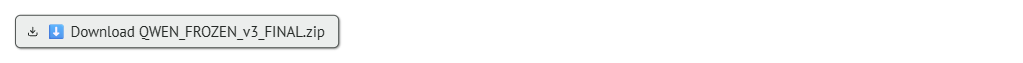

In [ ]:
QWEN_FROZEN_DIR = "QWEN_FROZEN_v3_FINAL"
os.makedirs(QWEN_FROZEN_DIR, exist_ok=True)

files_to_freeze = [
    "QWEN_FREEZE_REPORT.md",
    # §14-16 canonical caches
    "cache",  # directory — copied via copytree below
    # §12 corrected RefCOCO
    "refcoco_v3_corrected_results.jsonl",
    "refcoco_v3_full_metrics.jsonl",
    "section12_refcoco_full_metrics.csv",
    "outputs/refcoco_validation",  # directory
    "refcoco_v3_spotchecks",  # directory
    # §17-20, §23 stats/tables
    "primary_method_stats.json",
    "ablation_findings_v3.json",
    "calibration_reliability_table.csv",
    "figure_reliability_diagram.png",
    "table_gate_feature_ablation.csv",
    "figure_gate_feature_ablation.png",
    "category_analysis_v3.csv",
    "efficiency_v3_tau06.jsonl",
    "efficiency_v3_summary.json",
    # §21/22 faithfulness
    "faithfulness_v3_n500.jsonl",
    "faithfulness_v3_summary.json",
    # sanity + reproducibility
    "sanity_check_results.json",
    "reproducibility_statement.json",
]

copied, missing = [], []
for item in files_to_freeze:
    src = item
    if not os.path.exists(src):
        missing.append(item)
        continue
    dst = os.path.join(QWEN_FROZEN_DIR, os.path.basename(item.rstrip("/")))
    if os.path.isdir(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
    else:
        shutil.copy(src, QWEN_FROZEN_DIR)
    copied.append(item)

print(f"Copied {len(copied)} items")
if missing:
    print(f"NOT FOUND (skipped): {missing}")

# Create ZIP of the entire QWEN_FROZEN_v3_FINAL folder
zip_path = shutil.make_archive(
    base_name="QWEN_FROZEN_v3_FINAL",
    format="zip",
    root_dir=QWEN_FROZEN_DIR
)
print(f"ZIP created successfully: {zip_path}")

# Download button
download_button_frozen = mo.download(
    data=open(zip_path, "rb").read(),
    filename="QWEN_FROZEN_v3_FINAL.zip",
    label="⬇️ Download QWEN_FROZEN_v3_FINAL.zip",
)
download_button_frozen